<a href="https://colab.research.google.com/github/AviramNisimyan/SpeckleProject/blob/main/Deep_Speckle_DiT_Pixel_X0_ContrastiveEncoder_EndToEnd_OutputConv_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Deep Speckle — DiT with a contrastive Speckle encoder, unseen diffuser held out

**The experiment.** Direction 2: a separate encoder turns the Speckle into a *global representation*, and
the diffusion Transformer is conditioned on it. The goal is a representation that does not depend on the
diffuser, tested on a diffuser that was never seen in training. Training uses D1–D3 only; D4 is held out.

**Everything is in this notebook, in two stages.**

1. **Stage 1 — the encoder (Cell 9).** A Global Transformer (Speckle -> 64 tokens) with a contrastive head
   and a small direct decoder is trained on batches of 4 objects x 3 diffusers with
   `reconstruction loss + 0.12 x contrastive loss` (the same object through different diffusers must get
   a similar vector). The log of this training is saved next to the weights.
2. **Stage 2 — the diffusion model (Cells 13–14).** The official Meta `DiT` and `diffusion.create_diffusion`
   (https://github.com/facebookresearch/DiT), no VAE, x0-prediction. The 64 encoder tokens enter every DiT
   block through the attention; the contrastive vector is added to the timestep embedding (adaLN-Zero).

**What changed in this version of the notebook**

| | Previous version (results in `DiT_Pixel_X0_ContrastiveEncoder_D4HeldOut`) | This version |
|---|---|---|
| Encoder | loaded from an older notebook's checkpoint (its step 2,500), frozen | trained here in Stage 1, with a saved log |
| Encoder during diffusion training | frozen | `ENCODER_TRAINABLE = True`: trains end-to-end with the DiT |
| Contrastive loss during diffusion training | none | kept as a live regulariser (weight 0.12) |
| Batch | 8 measurements | 4 objects x 2 of the diffusers D1–D3 = 8 measurements (pairs for the contrastive loss) |
| Updates | 100,000 | 60,000 |
| Loss logging, checkpoints, saving | every 10,000 updates; best Dice, last; replace in place | every epoch; best loss, best Dice, last; new file per save, verified |
| Extra test | — | same-object retrieval across diffusers, including D4 (Cell 18) |

`ENCODER_TRAINABLE = False` reproduces the frozen-encoder setting inside this notebook.
`USE_OUTPUT_CONV = True` adds a 3x3 residual convolution after the DiT's unpatchify (a separate experiment).

**Choices made here that were not specified by the supervisor** (to be confirmed): the encoder is
initialised from Stage 1 and the DiT from scratch; the encoder learning rate in Stage 2 equals the DiT's
(1e-4); the encoder's direct decoder is not trained in Stage 2; the Stage 1 checkpoint is selected by the
validation PSNR of the direct reconstruction, as in the older notebook.

**Unchanged:** the object split (444 train / 96 validation objects, D1–D3; 60 sealed evaluation objects; D4
held out; split seed 31114), the preprocessing (2x2 binning, max-normalisation, binary target), the encoder
architecture and its losses (Cells 7–8 are the cells of the older notebook, verbatim).

**D4** was looked at in older experiments, so D4 numbers are a held-out test of the diffuser, not a
blind test. No checkpoint and no hyper-parameter is chosen with D4 or with the 60 evaluation objects.

In [ ]:
#@title 1. Configuration
SEED = 2607                        # same as the previous version of this notebook
SPLIT_SEED = 31114                 # do not change: the object split of this experiment
TRAIN_DIFFUSERS = ('1', '2', '3')
HELDOUT_DIFFUSER = '4'
TRAIN_OBJECT_FRACTION = .70
VALIDATION_OBJECT_FRACTION = .15

# ---- Stage 1: the Speckle encoder (Global Transformer + contrastive head + direct decoder) ----
ENCODER_WIDTH, ENCODER_DEPTH, ENCODER_HEADS, PATCH_SIZE = 128, 3, 4, 32
CONTRASTIVE_WEIGHT = .12           # weight of the contrastive loss, in Stage 1 and as the live regulariser in Stage 2
TEMPERATURE = .15
ENCODER_PRETRAIN_STEPS = 10_000    # batches of 4 objects x 3 diffusers
ENCODER_PRETRAIN_LR = 2e-4
ENCODER_PRETRAIN_VAL_EVERY = 500
ENCODER_SELECT_BY = 'VAL_PSNR'     # as in the older notebook: PSNR of the encoder's direct reconstruction on validation
ENCODER_RESULTS_NAME = 'DiT_Direction2_Encoder_Stage1'    # shared by all Stage 2 variants, so they start from the same encoder

# ---- Stage 2: diffusion ----
ENCODER_TRAINABLE = True           # True: end-to-end (the encoder trains with the DiT) | False: frozen encoder
ENCODER_FINETUNE_LR = 1e-4
OBJECTS_PER_BATCH = 4
VIEWS_PER_OBJECT = 2               # each object through 2 of the diffusers D1-D3 -> pairs for the contrastive loss
BATCH_SIZE = OBJECTS_PER_BATCH * VIEWS_PER_OBJECT          # 8 measurements, as in the other runs
TRAIN_STEPS = 60_000               # optimizer updates (111 per epoch)
LR = 1e-4                          # Meta DiT value, AdamW, weight decay 0
EMA_DECAY = 0.9999                 # Meta DiT value (with warm-up)
TRAIN_TIMESTEPS = 1000             # linear schedule, official create_diffusion
SAMPLE_STEPS = 50                  # DDIM steps

DIT_HIDDEN, DIT_DEPTH, DIT_HEADS = 384, 12, 6   # DiT-S
IMAGE_PATCH = 16                   # 256 image tokens
USE_ENCODER_TOKENS = True          # encoder tokens through the attention
USE_CONTRASTIVE_GLOBAL = True      # contrastive vector next to the time embedding (adaLN-Zero)
USE_OUTPUT_CONV = True             # 3x3 residual convolution after unpatchify

RUN_SANITY = True                  # 4-pair overfit + Speckle-swap test
SANITY_GATE = True                 # stop before the long run if the test fails
SANITY_STEPS = 2500
SANITY_LR = 2e-4
RUN_TRAINING = True
EVAL_EVERY = 10_000                # full DDIM reconstruction on a fixed validation subset
EVAL_SUBSET = 48
VAL_LOSS_EVERY_EPOCHS = 2          # validation loss on all 288 measurements
CHECKPOINT_EVERY = 5_000           # resumable checkpoint on Drive
PROGRESS_EVERY = 500
RUN_D4_EVAL = True                 # runs after the checkpoints are fixed; D4 is never used for selection
RESULTS_NAME = 'DiT_Pixel_X0_ContrastiveEncoder_D4HeldOut_EndToEnd_OutputConv'    # use a new name for every variant
REPORT_PREFIX = 'dir2_endtoend_conv_'

assert USE_ENCODER_TOKENS or USE_CONTRASTIVE_GLOBAL, 'The model needs at least one conditioning pathway'
assert TRAIN_DIFFUSERS == ('1', '2', '3') and HELDOUT_DIFFUSER == '4'
assert 2 <= VIEWS_PER_OBJECT <= 3 and OBJECTS_PER_BATCH >= 2
print('DiT-S | pixel space | x0-prediction | contrastive encoder,', 'end-to-end' if ENCODER_TRAINABLE else 'frozen',
      '| D1-D3 train, D4 held out | steps:', TRAIN_STEPS)

DiT-S | pixel space | x0-prediction | contrastive encoder, end-to-end | D1-D3 train, D4 held out | steps: 60000


In [ ]:
#@title 2. Install dependencies
%pip -q install 'timm==0.9.16' 'scikit-image>=0.24' 'pandas>=2.1'

In [ ]:
#@title 3. Imports, Drive, official DiT source, results directory
import os, sys, csv, re, json, math, time, copy, random, hashlib, shutil, subprocess
from pathlib import Path
from collections import OrderedDict
from concurrent.futures import ThreadPoolExecutor
import numpy as np, pandas as pd
from PIL import Image
import torch, torch.nn as nn, torch.nn.functional as F
from skimage.metrics import structural_similarity
import matplotlib.pyplot as plt
from google.colab import drive

MYDRIVE = Path('/content/drive/MyDrive')
if not MYDRIVE.is_dir():
    drive.mount('/content/drive')
assert MYDRIVE.is_dir(), 'Google Drive mount did not succeed'
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
assert DEVICE.type == 'cuda', 'In Colab: Runtime > Change runtime type > T4 GPU'
print('GPU:', torch.cuda.get_device_name(0), '| Torch:', torch.__version__)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True

META_REPO = Path('/content/official_Meta_DiT')
if not (META_REPO / 'models.py').is_file():
    subprocess.run(['git', 'clone', '--depth', '1', 'https://github.com/facebookresearch/DiT.git',
                    str(META_REPO)], check=True)
assert (META_REPO / 'models.py').is_file() and (META_REPO / 'diffusion/__init__.py').is_file()
repo_sha = subprocess.check_output(['git', '-C', str(META_REPO), 'rev-parse', 'HEAD'], text=True).strip()
if str(META_REPO) not in sys.path:
    sys.path.insert(0, str(META_REPO))
from models import DiT
from diffusion import create_diffusion

PROJECT = MYDRIVE / 'Speckle_Project'
RESULTS_DIR = PROJECT / RESULTS_NAME
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR = PROJECT / 'DiT_report_for_supervisor'
ENCODER_DIR = PROJECT / ENCODER_RESULTS_NAME
ENCODER_DIR.mkdir(parents=True, exist_ok=True)
assert (MYDRIVE / 'TranSpeckle/data_sets/2400').is_dir(), 'Missing TranSpeckle/data_sets/2400'
print('Official DiT revision:', repo_sha)
print('Results directory:', RESULTS_DIR)

GPU: Tesla T4 | Torch: 2.14.1+cu130
Official DiT revision: ed81ce2229091fd4ecc9a223645f95cf379d582b
Results directory: /content/drive/MyDrive/Speckle_Project/DiT_Pixel_X0_ContrastiveEncoder_D4HeldOut_EndToEnd_OutputConv


## Data: object split with D4 held out, reference preprocessing

In [ ]:
#@title 4. Reference preprocessing (2x2 binning, max-normalisation, binary target, x_0 in {-1,+1})
def binning_2x2(image):
    if image.ndim != 2:
        raise ValueError('Expected a two-dimensional grayscale image')
    height, width = image.shape
    if height % 2 != 0 or width % 2 != 0:
        raise ValueError('Image dimensions must be divisible by 2')
    pixels = image.astype(np.float32)
    return pixels.reshape(height // 2, 2, width // 2, 2).mean(axis=(1, 3))

def prepare_pair(speckle_binned, target_binned):
    speckle_max = float(speckle_binned.max())
    if speckle_max <= 0:
        raise ValueError('Speckle image has no positive intensity')
    condition = (speckle_binned / speckle_max).astype(np.float32)
    target_mask = (target_binned > 0).astype(np.float32)
    x_0 = 2.0 * target_mask - 1.0
    return condition, target_mask, x_0

def load_pair(paths):
    speckle_path, target_path = paths
    with Image.open(speckle_path) as image:
        speckle = np.array(image)
    with Image.open(target_path) as image:
        target = np.array(image if image.mode in ('L', 'I', 'I;16', 'I;16L', 'I;16B', 'F', '1') else image.convert('L'))
    if speckle.shape != (512, 512) or target.shape != (512, 512):
        raise ValueError(f'Expected 512x512, got {speckle.shape} and {target.shape}: {speckle_path}')
    condition, target_mask, _ = prepare_pair(binning_2x2(speckle), binning_2x2(target))
    return condition, target_mask.astype(np.uint8)

In [ ]:
#@title 5. TranSpeckle 2400 - verified filename families, object-wise split, D4 sealed
# Replace only Cell 6.  Uses ONLY TranSpeckle/data_sets/2400.
# Supports BOTH x1_0.tif and x1_big_0.tif (and analogous x2/x3/x4).
# No TIFF pixel data are read here. Cell 8 verifies actual GT matches across D1-D3.

from pathlib import Path
from collections import Counter, defaultdict
import hashlib
import json
import re
import numpy as np

DATA_ROOT_6 = Path('/content/drive/MyDrive/TranSpeckle/data_sets')
TRAIN_SET_6 = DATA_ROOT_6 / '2400'
if not TRAIN_SET_6.is_dir():
    raise FileNotFoundError(f'Missing official TranSpeckle dataset: {TRAIN_SET_6}')
if tuple(map(str, TRAIN_DIFFUSERS)) != ('1', '2', '3') or str(HELDOUT_DIFFUSER) != '4':
    raise RuntimeError('This experiment requires D1-D3 for training and D4 sealed for evaluation.')

# Examples: x1_0.tif -> (D1, standard, 0)
#           x1_big_0.tif -> (D1, big, 0)
# A variant is a filename FAMILY, NOT a verified Digit/Letter class.
pattern6 = re.compile(
    r'^x(?P<diffuser>[1-4])_(?:(?P<family>[A-Za-z][A-Za-z0-9_-]*)_)?(?P<object_number>\d+)$',
    re.IGNORECASE,
)

def parse_filename6(filename):
    m = pattern6.fullmatch(Path(filename).stem)
    if m is None:
        raise ValueError(f'Unsupported TranSpeckle filename: {filename}')
    return (m.group('diffuser'),
            (m.group('family') or 'standard').lower(),
            str(int(m.group('object_number'))))

# Quick deterministic parser checks.
assert parse_filename6('x1_0.tif') == ('1', 'standard', '0')
assert parse_filename6('x1_big_0.tif') == ('1', 'big', '0')
assert parse_filename6('x4_big_239.tif') == ('4', 'big', '239')

def read_metadata6(split):
    """Collect x/y paths only; do NOT inspect image content (especially D4/EVAL)."""
    xdir = TRAIN_SET_6 / f'x_{split}'
    ydir = TRAIN_SET_6 / f'y_{split}'
    if not xdir.is_dir() or not ydir.is_dir():
        raise FileNotFoundError(f'Missing paired folders: {xdir}, {ydir}')

    extensions = {'.tif', '.tiff'}
    xfiles = sorted((p for p in xdir.iterdir()
                     if p.is_file() and p.suffix.lower() in extensions),
                    key=lambda p: p.name)
    yfiles = {p.name: p for p in ydir.iterdir()
              if p.is_file() and p.suffix.lower() in extensions}
    if not xfiles or len(xfiles) != len(yfiles):
        raise RuntimeError(f'{split}: Speckle files={len(xfiles)}; GT files={len(yfiles)}.')

    by_object = defaultdict(dict)
    counts = Counter()
    unparsed = []
    for x_path in xfiles:
        y_path = yfiles.get(x_path.name)
        if y_path is None:
            raise RuntimeError(f'{split}: GT is missing for {x_path.name}')
        try:
            d, family, object_number = parse_filename6(x_path.name)
        except ValueError:
            unparsed.append(x_path.name)
            continue

        key = (family, object_number)
        if d in by_object[key]:
            raise RuntimeError(f'{split}: duplicate object/view: {key}, diffuser={d}')
        by_object[key][d] = dict(
            kind=family, object_id=object_number, diffuser=d,
            speckle_path=str(x_path), gt_path=str(y_path),
            source_split=split, filename=x_path.name,
        )
        counts[(family, d)] += 1

    if unparsed:
        raise RuntimeError(
            f'{split}: {len(unparsed)} filenames do not match the supported pattern. '
            f'First examples: {unparsed[:12]}. Do not guess identity.'
        )

    print(f'\nOFFICIAL {split.upper()}: {len(xfiles)} paired measurements, '
          f'{len(by_object)} filename-based four-view candidate objects')
    print('File counts by filename family and diffuser:')
    for family in sorted({family for family, _ in counts}):
        print(f'  {family}:', {d: counts[(family, d)] for d in ('1','2','3','4')})

    needed = {'1','2','3','4'}
    incomplete = [(k, sorted(needed-set(v))) for k, v in by_object.items()
                  if set(v) != needed]
    if incomplete:
        raise RuntimeError(
            f'{split}: {len(incomplete)} filename-based objects lack some diffusers. '
            f'First 10: {incomplete[:10]}. '
            'Check whether the source is actually a four-diffuser dataset.'
        )
    return dict(by_object)

# Read METADATA from original split. Official validation is sealed evaluation here.
official_train6 = read_metadata6('train')
official_eval6 = read_metadata6('valid')
if len(official_train6) < 100 or len(official_eval6) < 10:
    raise RuntimeError('Too few complete four-view objects for a full training experiment.')
if set(official_train6).intersection(official_eval6):
    raise RuntimeError('Same filename-family/object-number appears in official train and valid!')

# Be conservative: different filename families sharing the same numeric ID
# stay in the SAME internal split, to reduce possible object-identity leakage.
# This does not assert that different families with the same ID are identical objects.
object_ids6 = sorted({k[1] for k in official_train6}, key=lambda x: int(x))
rng6 = np.random.default_rng(SPLIT_SEED)
order6 = rng6.permutation(len(object_ids6))
ratio6 = TRAIN_OBJECT_FRACTION / (TRAIN_OBJECT_FRACTION + VALIDATION_OBJECT_FRACTION)
n_train_ids6 = int(len(object_ids6) * ratio6)
train_ids6 = {object_ids6[i] for i in order6[:n_train_ids6]}
val_ids6 = set(object_ids6) - train_ids6

sortkey6 = lambda k: (k[0], int(k[1]))
splits = {
    'TRAIN': sorted((k for k in official_train6 if k[1] in train_ids6), key=sortkey6),
    'VAL': sorted((k for k in official_train6 if k[1] in val_ids6), key=sortkey6),
    'EVAL': sorted(official_eval6, key=sortkey6),
}
complete = {**official_train6, **official_eval6}
records = [r for views in complete.values() for r in views.values()]

if not splits['TRAIN'] or not splits['VAL'] or not splits['EVAL']:
    raise RuntimeError('One of TRAIN/VAL/EVAL is empty after the object-wise split.')
assert len(set().union(*(set(v) for v in splits.values()))) == len(complete)
assert all(set(splits[a]).isdisjoint(splits[b]) for a,b in
           [('TRAIN','VAL'),('TRAIN','EVAL'),('VAL','EVAL')])
assert all(set(complete[k]) == {'1','2','3','4'}
           for g in splits.values() for k in g)

# Prevent silent reuse of a checkpoint from a differently parsed dataset/split.
manifest_for_hash6 = {
    'dataset': str(TRAIN_SET_6),
    'object_split': {name: keys for name,keys in splits.items()},
    'file_mapping': {f'{family}:{obj}': {d: complete[(family,obj)][d]['filename']
                       for d in sorted(complete[(family,obj)])}
                     for family,obj in sorted(complete, key=sortkey6)},
    'diffusers_train': list(TRAIN_DIFFUSERS),
    'heldout_diffuser': str(HELDOUT_DIFFUSER),
    'preprocessing': '2x2-bin-maxnorm-binary-GT-256',
}
SPLIT_FINGERPRINT = hashlib.sha256(
    json.dumps(manifest_for_hash6, sort_keys=True).encode()
).hexdigest()

print('\n=== DATA PLAN (before any training) ===')
for label, keys in splits.items():
    print(f'{label}: {len(keys)} object-family pairs | '
          f'{len(keys)*3} D1-D3 measurements | '
          f'{len(keys)} held-out D4 file paths (not opened)')
    print('  filename families:', dict(Counter(k[0] for k in keys)))
print('All four-view candidate groups:', len(complete))
print('Distinct numeric IDs in official TRAIN:', len(object_ids6))
print('Split fingerprint:', SPLIT_FINGERPRINT[:16])
print('D4 and official EVAL image data were NOT read.')
print('NEXT: Run Cell 8; it checks exact GT consistency across D1/D2/D3.')
print('NOTE: Filename family (e.g. big) is not assumed to mean Digit or Letter.')


OFFICIAL TRAIN: 2160 paired measurements, 540 filename-based four-view candidate objects
File counts by filename family and diffuser:
  big: {'1': 270, '2': 270, '3': 270, '4': 270}
  standard: {'1': 270, '2': 270, '3': 270, '4': 270}

OFFICIAL VALID: 240 paired measurements, 60 filename-based four-view candidate objects
File counts by filename family and diffuser:
  big: {'1': 30, '2': 30, '3': 30, '4': 30}
  standard: {'1': 30, '2': 30, '3': 30, '4': 30}

=== DATA PLAN (before any training) ===
TRAIN: 444 object-family pairs | 1332 D1-D3 measurements | 444 held-out D4 file paths (not opened)
  filename families: {'big': 222, 'standard': 222}
VAL: 96 object-family pairs | 288 D1-D3 measurements | 96 held-out D4 file paths (not opened)
  filename families: {'big': 48, 'standard': 48}
EVAL: 60 object-family pairs | 180 D1-D3 measurements | 60 held-out D4 file paths (not opened)
  filename families: {'big': 30, 'standard': 30}
All four-view candidate groups: 600
Distinct numeric IDs in 

TRAIN: loaded 1332 processed measurements from cache in DiT_Pixel_X0_ContrastiveEncoder_D4HeldOut
VAL: loaded 288 processed measurements from cache in DiT_Pixel_X0_ContrastiveEncoder_D4HeldOut
TRAIN measurements: 1332 | VAL measurements: 288
Speckle range: 0.0 1.0 | target values: [0, 1]
Mean foreground fraction: train 0.1155 | validation 0.1142
No D4 image and no official x_valid/y_valid image was opened.


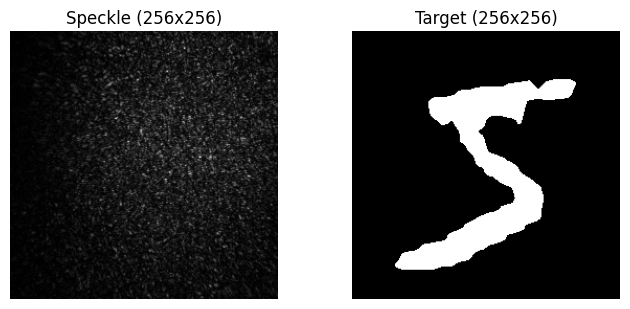

In [ ]:
#@title 6. Load TRAIN and VAL (D1-D3 only, threaded, cached) and verify the target is identical across diffusers
EXPECTED_SPLIT_FINGERPRINT = 'bd1dc0429c80e91b'     # the split of this experiment (also used by the Direction-1 notebook)
assert SPLIT_FINGERPRINT[:16] == EXPECTED_SPLIT_FINGERPRINT, (
    'The object split differs from the experiment split: ' + SPLIT_FINGERPRINT[:16])
FAMILY_LABEL = {'big': 'Digit', 'standard': 'Letter'}   # naming used in the shared reports (checked by eye on objects 270, 271)
# Processed arrays are identical for the same split fingerprint and preprocessing, so an existing cache is reused (read only).
CACHE_DIRS = [RESULTS_DIR, PROJECT / 'DiT_Pixel_X0_ContrastiveEncoder_D4HeldOut']

def load_views(split):
    keys = splits[split]
    pairs = [(complete[k][d]['speckle_path'], complete[k][d]['gt_path']) for k in keys for d in TRAIN_DIFFUSERS]
    name = f'cache_{split}_{SPLIT_FINGERPRINT[:12]}.npz'
    X = M = None
    for folder in CACHE_DIRS:
        if (folder / name).is_file():
            data = np.load(folder / name)
            if len(data['X']) == len(pairs):
                X, M = data['X'], data['M']
                print(f'{split}: loaded {len(X)} processed measurements from cache in {folder.name}')
                break
    if X is None:
        X = np.zeros((len(pairs), 256, 256), np.float32); M = np.zeros((len(pairs), 256, 256), np.uint8)
        tick = time.time()
        with ThreadPoolExecutor(max_workers=16) as pool:
            for i, (condition, mask) in enumerate(pool.map(load_pair, pairs)):
                X[i], M[i] = condition, mask
                if (i + 1) % 300 == 0 or i + 1 == len(pairs):
                    print(f'{split}: {i + 1}/{len(pairs)} measurements | {time.time() - tick:.0f}s', flush=True)
        local = Path('/content') / name
        np.savez(local, X=X, M=M); shutil.copy(local, RESULTS_DIR / name)
    Mv = M.reshape(len(keys), 3, 256, 256)
    if not ((Mv[:, 0] == Mv[:, 1]).all() and (Mv[:, 0] == Mv[:, 2]).all()):
        raise RuntimeError(f'{split}: an object has different targets across D1/D2/D3. Stop: the pairing is wrong.')
    names = [Path(complete[k][d]['filename']).stem for k in keys for d in TRAIN_DIFFUSERS]
    family = [FAMILY_LABEL.get(k[0], k[0]) for k in keys for d in TRAIN_DIFFUSERS]
    diffuser = ['D' + d for k in keys for d in TRAIN_DIFFUSERS]
    return torch.from_numpy(X), torch.from_numpy(M), names, family, diffuser

Xtr, Mtr, TRAIN_NAMES, _, _ = load_views('TRAIN')            # [N,256,256] float32 / uint8, order: object, then D1,D2,D3
Xva, Mva, VAL_NAMES, VAL_FAMILY, VAL_DIFFUSER = load_views('VAL')
assert len(splits['TRAIN']) == 444 and len(splits['VAL']) == 96 and len(splits['EVAL']) == 60, (
    len(splits['TRAIN']), len(splits['VAL']), len(splits['EVAL']))
assert Xtr.dtype == torch.float32 and Mtr.dtype == torch.uint8
assert tuple(Xtr.shape) == (1332, 256, 256) and tuple(Xva.shape) == (288, 256, 256)
assert torch.isfinite(Xtr).all() and torch.isfinite(Xva).all()
assert float(Xtr.min()) >= 0 and abs(float(Xtr.amax(dim=(1, 2)).min()) - 1.0) < 1e-6
assert set(torch.unique(Mtr).tolist()) <= {0, 1}
assert all(n.startswith(('x1_', 'x2_', 'x3_')) for n in TRAIN_NAMES + VAL_NAMES), 'A D4 file reached the training data'
print('TRAIN measurements:', len(Mtr), '| VAL measurements:', len(Mva))
print('Speckle range:', float(Xtr.min()), float(Xtr.max()), '| target values:', torch.unique(Mtr).tolist())
print('Mean foreground fraction: train %.4f | validation %.4f' % (float(Mtr.float().mean()), float(Mva.float().mean())))
print('No D4 image and no official x_valid/y_valid image was opened.')

def get_batch(X, M, ids):
    """Return (x_0 in {-1,+1}, Speckle in [0,1]) as float32 tensors of shape [B,1,256,256]."""
    ids = torch.as_tensor(ids, dtype=torch.long)
    return (2.0 * M[ids].float() - 1.0)[:, None], X[ids][:, None]

# Object-major views used by the encoder cells: [objects, 3 diffusers, 1, 256, 256]
Xtrain = Xtr.reshape(-1, 3, 1, 256, 256); Xval = Xva.reshape(-1, 3, 1, 256, 256)
Ytrain = Mtr.reshape(-1, 3, 1, 256, 256); Yval = Mva.reshape(-1, 3, 1, 256, 256)

fig, ax = plt.subplots(1, 2, figsize=(7, 3.2))
ax[0].imshow(Xtr[0], cmap='gray', vmin=0, vmax=1); ax[0].set_title('Speckle (256x256)')
ax[1].imshow(Mtr[0], cmap='gray', vmin=0, vmax=1); ax[1].set_title('Target (256x256)')
for a in ax: a.axis('off')
plt.tight_layout(); plt.show(); plt.close(fig)

## Stage 1: the Speckle encoder

Cells 7 and 8 are the encoder, its losses and its validation, copied verbatim from the older notebook.
Cell 9 trains it here and saves the weights **and the training log**, so the encoder used below is fully
documented. If the same Stage 1 was already run, its saved result is loaded instead of training again.

In [ ]:
#@title 7. Global Transformer, contrastive projector, decoder and losses

class GlobalTransformer(nn.Module):
    def __init__(self,width=ENCODER_WIDTH,depth=ENCODER_DEPTH,heads=ENCODER_HEADS):
        super().__init__()
        self.patch=nn.Conv2d(1,width,kernel_size=PATCH_SIZE,stride=PATCH_SIZE)
        self.pos=nn.Parameter(torch.randn(1,64,width)*.02)
        block=nn.TransformerEncoderLayer(d_model=width,nhead=heads,dim_feedforward=3*width,
                                          batch_first=True,norm_first=True,dropout=0.0,activation='gelu')
        self.layers=nn.TransformerEncoder(block,depth,enable_nested_tensor=False)
        self.norm=nn.LayerNorm(width)
    def forward(self,x):
        z=self.patch(x).flatten(2).transpose(1,2)+self.pos
        return self.norm(self.layers(z))

class GlobalReconstructionModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder=GlobalTransformer()
        self.projector=nn.Sequential(nn.LayerNorm(64*128),nn.Linear(64*128,256),nn.GELU(),nn.Linear(256,128))
        self.direct=nn.Sequential(
            nn.ConvTranspose2d(128,64,4,2,1),nn.GroupNorm(8,64),nn.SiLU(),
            nn.ConvTranspose2d(64,48,4,2,1),nn.GroupNorm(8,48),nn.SiLU(),
            nn.ConvTranspose2d(48,32,4,2,1),nn.GroupNorm(8,32),nn.SiLU(),
            nn.ConvTranspose2d(32,16,4,2,1),nn.GroupNorm(8,16),nn.SiLU(),
            nn.ConvTranspose2d(16,8,4,2,1),nn.GroupNorm(8,8),nn.SiLU(),
            nn.Conv2d(8,1,3,padding=1),nn.Tanh())
    def forward(self,x):
        tok=self.encoder(x)
        z=F.normalize(self.projector(tok.flatten(1)),dim=-1,eps=1e-8)
        out=self.direct(tok.transpose(1,2).reshape(-1,128,8,8))
        return tok,z,out

def contrastive_loss(z,nobjects):
    labels=torch.arange(nobjects,device=z.device).repeat_interleave(3)
    logits=(z.float()@z.float().T)/TEMPERATURE
    mask=torch.eye(len(labels),device=z.device,dtype=torch.bool)
    positive=labels[:,None].eq(labels[None,:]) & (~mask)
    logits=logits.masked_fill(mask,-1e4)
    logs=logits-torch.logsumexp(logits,dim=1,keepdim=True)
    return -((logs*positive.float()).sum(1)/positive.sum(1).clamp_min(1)).mean()

def reconstruction_loss(pred,gt):
    p=((pred.float()+1)/2).clamp(1e-5,1-1e-5)
    t=((gt.float()+1)/2).clamp(0,1)
    # BCE MUST be computed outside autocast.
    with torch.autocast(device_type=pred.device.type,enabled=False):
        bce=F.binary_cross_entropy(p.float(),t.float())
    dice=1-((2*(p*t).sum((1,2,3))+1)/(p.sum((1,2,3))+t.sum((1,2,3))+1)).mean()
    return bce + .5*dice + .1*F.mse_loss(pred.float(),gt.float())

def to_minus_one_one(y01):return y01*2-1

def im_metrics(output,truth):
    a=np.asarray(output,dtype=np.float32).reshape(256,256)
    b=np.asarray(truth,dtype=np.float32).reshape(256,256)
    a=np.clip((a+1)/2,0,1);b=np.clip((b+1)/2,0,1)
    mse=float(np.mean((a-b)**2));psnr=float(-10*np.log10(max(1e-12,mse)))
    ssim=float(structural_similarity(b,a,data_range=1))
    aa=(a>.5);bb=(b>.5)
    inter=np.logical_and(aa,bb).sum();union=np.logical_or(aa,bb).sum()
    dice=float((2*inter+1)/(aa.sum()+bb.sum()+1))
    iou=float((inter+1)/(union+1))
    if np.std(a)<1e-9 or np.std(b)<1e-9: pcc=float('nan')
    else: pcc=float(np.corrcoef(a.flatten(),b.flatten())[0,1])
    return dict(PSNR=psnr,SSIM=ssim,Dice=dice,IoU=iou,PCC=pcc)

# Model shape and gradient smoke test, independent of data.
global_model=GlobalReconstructionModel().to(DEVICE)
with torch.autocast('cuda',enabled=True):
    probe_tokens,probe_z,probe_y=global_model(torch.rand(2,1,256,256,device=DEVICE))
assert probe_tokens.shape==(2,64,128) and probe_z.shape==(2,128) and probe_y.shape==(2,1,256,256)
(probe_y.square().mean()+probe_z.square().mean()).backward()
assert any(p.grad is not None for p in global_model.encoder.parameters())
global_model.zero_grad(set_to_none=True)
print('GLOBAL ENCODER SHAPE/GRADIENT PASS | total params:',sum(p.numel() for p in global_model.parameters()))

GLOBAL ENCODER SHAPE/GRADIENT PASS | total params: 2998081


In [ ]:
#@title 8. Validation: reconstruction and cross-diffuser retrieval (KNOWN diffusers only)

@torch.inference_mode()
def encode_split(model,X,keys,batch_objects=4):
    model.eval();tokens=[];emb=[];coarse=[]
    model.to(DEVICE)
    for st in range(0,len(keys),batch_objects):
        x=X[st:st+batch_objects].reshape(-1,1,256,256).float().to(DEVICE)
        with torch.autocast('cuda',enabled=True):t,z,c=model(x)
        tokens.append(t.float().cpu().reshape(-1,3,64,128))
        emb.append(z.float().cpu().reshape(-1,3,128))
        coarse.append(c.float().cpu().reshape(-1,3,1,256,256))
    return dict(tokens=torch.cat(tokens),z=torch.cat(emb),coarse=torch.cat(coarse))

def known_retrieval(z,keys):
    correct=total=0;reciprocal=0.
    for kind in sorted({k[0] for k in keys}):
        where=[i for i,k in enumerate(keys) if k[0]==kind]
        view=F.normalize(z[where].float(),dim=-1).numpy()
        for q in range(3):
            for g in range(3):
                if q==g:continue
                sim=view[:,q,:]@view[:,g,:].T
                order=np.argsort(-sim,axis=1,kind='stable')
                rank=np.argmax(order==np.arange(len(where))[:,None],axis=1)+1
                correct+=int((rank==1).sum());reciprocal+=float((1/rank).sum());total+=len(rank)
    return dict(Top1=correct/max(total,1),MRR=reciprocal/max(total,1))

@torch.inference_mode()
def validate_global(model):
    cache=encode_split(model,Xval,splits['VAL'])
    pred=cache['coarse'].reshape(-1,1,256,256)
    target=to_minus_one_one(Yval.float()).reshape(-1,1,256,256)
    val_psnr=float((-10*torch.log10((pred-target).square().flatten(1).mean(1).clamp_min(1e-12)/4)).mean())
    val_mse=float((pred-target).square().mean())
    ret=known_retrieval(cache['z'],splits['VAL'])
    return dict(VAL_MSE=val_mse,VAL_PSNR=val_psnr,VAL_Top1=ret['Top1'],VAL_MRR=ret['MRR'])

print('Validator ready. No D4 images opened.')

Validator ready. No D4 images opened.


Stage 1 was already run with this recipe: loading encoder_stage1_ec34ab303270.pt
 step  train_total  train_recon  train_contrast  VAL_MSE  VAL_PSNR  VAL_Top1  VAL_MRR
    1       1.5511       1.2642          2.3909   1.0856    5.6641    0.0330   0.1255
  500       0.6058       0.5074          0.8206   0.3113   11.4215    0.6042   0.7446
 1000       0.6618       0.5493          0.9367   0.2741   12.2272    0.6389   0.7767
 1500       0.4075       0.3091          0.8197   0.2644   12.4522    0.6372   0.7803
 2000       0.3205       0.2303          0.7523   0.2801   12.2025    0.6458   0.7817
 2500       0.2851       0.2008          0.7023   0.2831   12.1828    0.6701   0.7918
 3000       0.2285       0.1427          0.7144   0.2839   12.1734    0.6701   0.7973
 3500       0.2558       0.1688          0.7251   0.2871   12.1394    0.6458   0.7780
 4000       0.2326       0.1471          0.7123   0.2922   12.0714    0.6424   0.7740
 4500       0.1984       0.1134          0.7082   0.2876   

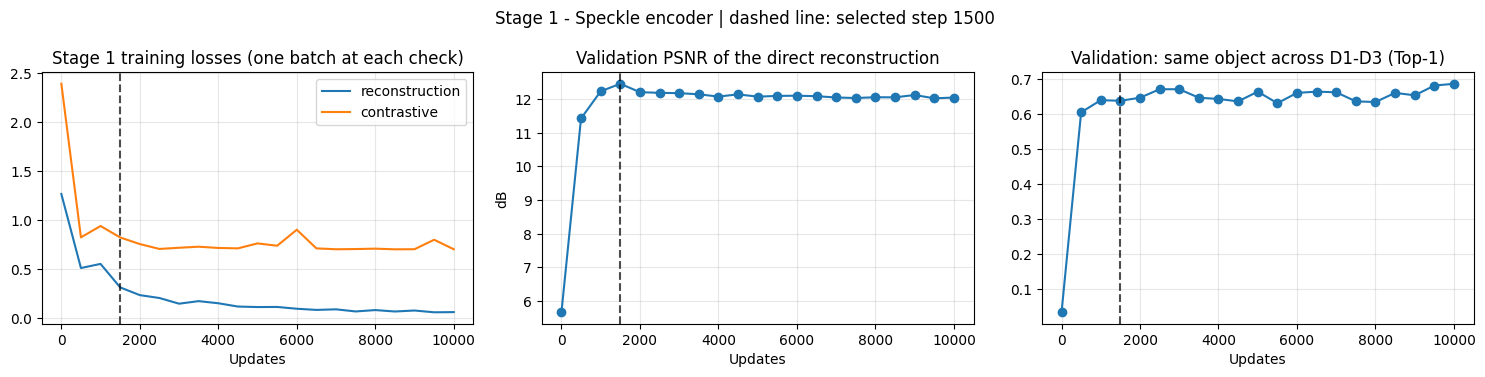

In [ ]:
#@title 9. Stage 1 - train the Speckle encoder (direct reconstruction + contrastive loss), with a saved log
ENCODER_RECIPE = dict(split=SPLIT_FINGERPRINT, width=ENCODER_WIDTH, depth=ENCODER_DEPTH, heads=ENCODER_HEADS, patch=PATCH_SIZE,
                      contrastive_weight=CONTRASTIVE_WEIGHT, temperature=TEMPERATURE, steps=ENCODER_PRETRAIN_STEPS,
                      lr=ENCODER_PRETRAIN_LR, val_every=ENCODER_PRETRAIN_VAL_EVERY, select_by=ENCODER_SELECT_BY,
                      objects_per_batch=4, views=3, seed=SEED)
ENCODER_RECIPE_HASH = hashlib.sha256(json.dumps(ENCODER_RECIPE, sort_keys=True).encode()).hexdigest()
ENCODER_FILE = ENCODER_DIR / ('encoder_stage1_%s.pt' % ENCODER_RECIPE_HASH[:12])

def file_sha256(path):
    digest = hashlib.sha256()
    with open(path, 'rb') as handle:
        for chunk in iter(lambda: handle.read(1 << 24), b''):
            digest.update(chunk)
    return digest.hexdigest()

@torch.inference_mode()
def encoder_outputs(net, X, batch=12):
    """X: Speckle images [N,256,256] -> (direct reconstruction [N,1,256,256], contrastive vector [N,128])."""
    net.to(DEVICE).eval(); outs = []; zs = []
    for st in range(0, len(X), batch):
        with torch.autocast('cuda', enabled=True):
            _, z, direct = net(X[st:st + batch][:, None].float().to(DEVICE))
        outs.append(direct.float().cpu()); zs.append(z.float().cpu())
    return torch.cat(outs), torch.cat(zs)

if ENCODER_FILE.is_file():
    encoder_ckpt = torch.load(ENCODER_FILE, map_location='cpu', weights_only=False)
    assert encoder_ckpt['recipe_hash'] == ENCODER_RECIPE_HASH, 'The saved Stage 1 encoder was made with a different recipe'
    print('Stage 1 was already run with this recipe: loading', ENCODER_FILE.name)
else:
    torch.manual_seed(SEED)
    global_model = GlobalReconstructionModel().to(DEVICE)
    optimizer_enc = torch.optim.AdamW(global_model.parameters(), lr=ENCODER_PRETRAIN_LR, weight_decay=1e-4)
    scaler_enc = torch.amp.GradScaler('cuda')
    rng_enc = torch.Generator(device='cpu').manual_seed(SEED + 12)
    encoder_log = []; best_score = -float('inf'); best_state = None; best_step_enc = 0; tick = time.time()
    for step in range(1, ENCODER_PRETRAIN_STEPS + 1):
        global_model.train()
        picked = torch.randperm(len(splits['TRAIN']), generator=rng_enc)[:4]             # 4 objects x 3 diffusers
        xb = Xtrain[picked].reshape(-1, 1, 256, 256).float().to(DEVICE)
        yb = to_minus_one_one(Ytrain[picked].reshape(-1, 1, 256, 256).float().to(DEVICE))
        optimizer_enc.zero_grad(set_to_none=True)
        with torch.autocast('cuda', enabled=True):
            tokens, z, direct = global_model(xb)
            loss_recon = reconstruction_loss(direct, yb)
            loss_contrast = contrastive_loss(z, len(picked))
            loss = loss_recon + CONTRASTIVE_WEIGHT * loss_contrast
        if not torch.isfinite(loss):
            raise RuntimeError(f'Non-finite encoder loss at step {step}')
        scaler_enc.scale(loss).backward()
        scaler_enc.unscale_(optimizer_enc)
        torch.nn.utils.clip_grad_norm_(global_model.parameters(), 1.0)
        scaler_enc.step(optimizer_enc); scaler_enc.update()
        if step == 1 or step % ENCODER_PRETRAIN_VAL_EVERY == 0 or step == ENCODER_PRETRAIN_STEPS:
            res = validate_global(global_model)
            encoder_log.append(dict(step=step, train_total=float(loss.detach()), train_recon=float(loss_recon.detach()),
                                    train_contrast=float(loss_contrast.detach()), **res))
            if res[ENCODER_SELECT_BY] > best_score:
                best_score = res[ENCODER_SELECT_BY]; best_step_enc = step
                best_state = {k: v.detach().cpu().clone() for k, v in global_model.state_dict().items()}
            print(f"ENCODER {step}/{ENCODER_PRETRAIN_STEPS} | train={float(loss.detach()):.4f} | val_PSNR={res['VAL_PSNR']:.2f} "
                  f"| val_MSE={res['VAL_MSE']:.4f} | val_retrieval={res['VAL_Top1']:.1%} | mins={(time.time() - tick) / 60:.1f}", flush=True)
    encoder_ckpt = dict(weights=best_state, best_step=best_step_enc, best_score=best_score, last_step=ENCODER_PRETRAIN_STEPS,
                        history=encoder_log, recipe=ENCODER_RECIPE, recipe_hash=ENCODER_RECIPE_HASH)
    local = Path('/content') / ENCODER_FILE.name
    torch.save(encoder_ckpt, local); shutil.copyfile(local, ENCODER_FILE)
    assert file_sha256(local) == file_sha256(ENCODER_FILE), 'The Drive copy of the Stage 1 encoder differs from the local file'
    del optimizer_enc, scaler_enc, best_state

global_model = GlobalReconstructionModel()
global_model.load_state_dict(encoder_ckpt['weights'], strict=True); global_model.eval()
for p in global_model.parameters(): p.requires_grad_(False)       # this copy stays as trained in Stage 1 (the baseline)
encoder_best_step = int(encoder_ckpt['best_step'])
encoder_table = pd.DataFrame(encoder_ckpt['history'])
encoder_table.to_csv(ENCODER_DIR / ('encoder_stage1_log_%s.csv' % ENCODER_RECIPE_HASH[:12]), index=False)
encoder_table.to_csv(RESULTS_DIR / 'encoder_stage1_log.csv', index=False)
print(encoder_table.round(4).to_string(index=False))
print('Selected Stage 1 encoder: step', encoder_best_step, 'of', int(encoder_ckpt['last_step']), '| criterion:', ENCODER_SELECT_BY,
      '| best retrieval was at step', int(encoder_table.loc[encoder_table.VAL_Top1.idxmax(), 'step']))
coarse_val, _ = encoder_outputs(global_model, Xva)       # direct reconstruction of the Stage 1 encoder: the baseline for the DiT
print('Stage 1 encoder on validation:', {k: round(v, 4) for k, v in validate_global(global_model).items()})
global_model.cpu(); torch.cuda.empty_cache()

fig, axs = plt.subplots(1, 3, figsize=(15, 3.8))
axs[0].plot(encoder_table.step, encoder_table.train_recon, label='reconstruction'); axs[0].plot(encoder_table.step, encoder_table.train_contrast, label='contrastive')
axs[0].set(title='Stage 1 training losses (one batch at each check)', xlabel='Updates'); axs[0].legend()
axs[1].plot(encoder_table.step, encoder_table.VAL_PSNR, marker='o'); axs[1].set(title='Validation PSNR of the direct reconstruction', xlabel='Updates', ylabel='dB')
axs[2].plot(encoder_table.step, encoder_table.VAL_Top1, marker='o'); axs[2].set(title='Validation: same object across D1-D3 (Top-1)', xlabel='Updates')
for a in axs:
    a.axvline(encoder_best_step, color='k', ls='--', alpha=.7); a.grid(alpha=.3)
fig.suptitle('Stage 1 - Speckle encoder | dashed line: selected step %d' % encoder_best_step)
plt.tight_layout(); fig.savefig(RESULTS_DIR / 'encoder_stage1.png', dpi=130, bbox_inches='tight'); plt.show(); plt.close(fig)

In [ ]:
#@title 10. Stage 2 model: official DiT + the Speckle encoder (tokens through attention, contrastive vector next to the time embedding)
class SpeckleConditioner(nn.Module):
    """Encoder features [B,65,128] -> (64 tokens for the attention, global vector for adaLN-Zero)."""
    def __init__(self, hidden, feat=128, n_tokens=64):
        super().__init__()
        self.token_proj = nn.Sequential(nn.LayerNorm(feat), nn.Linear(feat, hidden))
        self.pos = nn.Parameter(torch.zeros(1, n_tokens, hidden))
        self.type_embed = nn.Parameter(torch.zeros(1, 1, hidden))
        self.global_head = nn.Sequential(nn.Linear(feat, hidden), nn.SiLU(), nn.Linear(hidden, hidden))
        nn.init.normal_(self.pos, std=0.02); nn.init.normal_(self.type_embed, std=0.02)
        nn.init.normal_(self.global_head[-1].weight, std=0.02); nn.init.zeros_(self.global_head[-1].bias)

    def forward(self, cond):
        cond = cond.float()
        tokens = self.token_proj(cond[:, :64]) + self.pos + self.type_embed     # encoder tokens
        return tokens, self.global_head(cond[:, 64])                            # contrastive vector (scaled)

class SpeckleDiT(DiT):
    """Official DiT. Only the conditioning differs: the class-label table is replaced by a conditioner on the
    encoder's representation, and forward() appends the encoder tokens to the image tokens before the blocks."""
    def __init__(self, use_tokens=True, use_global=True, output_conv=False, **dit_kwargs):
        super().__init__(**dit_kwargs)
        hidden = self.pos_embed.shape[-1]
        self.y_embedder = nn.Identity()      # the ImageNet label table is not used
        self.speckle = SpeckleConditioner(hidden)
        self.use_tokens, self.use_global = use_tokens, use_global
        self.out_conv = nn.Conv2d(1, 1, kernel_size=3, padding=1) if output_conv else None
        if self.out_conv is not None:        # residual and zero-initialised: the model starts exactly as the plain DiT
            nn.init.zeros_(self.out_conv.weight); nn.init.zeros_(self.out_conv.bias)

    def forward(self, x, t, y):
        x = self.x_embedder(x) + self.pos_embed
        n_image = x.shape[1]
        tokens, global_vec = self.speckle(y)
        c = self.t_embedder(t)
        if self.use_global:
            c = c + global_vec
        if self.use_tokens:
            x = torch.cat([x, tokens.to(x.dtype)], dim=1)
        for block in self.blocks:
            x = block(x, c)
        x = self.unpatchify(self.final_layer(x[:, :n_image], c))
        if self.out_conv is not None:
            x = x + self.out_conv(x)
        return x

class JointModel(nn.Module):
    """Speckle image -> encoder -> (64 tokens, contrastive vector) -> DiT. One module, so the optimiser, the EMA and
    the checkpoints cover the encoder and the DiT together."""
    def __init__(self, encoder, dit):
        super().__init__()
        self.encoder, self.dit = encoder, dit

    def condition(self, speckle):
        tokens = self.encoder.encoder(speckle.float())
        z = F.normalize(self.encoder.projector(tokens.flatten(1)).float(), dim=-1, eps=1e-8)
        return torch.cat([tokens.float(), z.unsqueeze(1) * math.sqrt(128)], dim=1), z      # [B,65,128], [B,128]

    def forward(self, x, t, y):
        return self.dit(x, t, self.condition(y)[0])

def multi_view_contrastive_loss(z, n_objects, n_views):
    """The InfoNCE of Stage 1 for n_views measurements per object (rows ordered object by object)."""
    labels = torch.arange(n_objects, device=z.device).repeat_interleave(n_views)
    logits = (z.float() @ z.float().T) / TEMPERATURE
    mask = torch.eye(len(labels), device=z.device, dtype=torch.bool)
    positive = labels[:, None].eq(labels[None, :]) & (~mask)
    logits = logits.masked_fill(mask, -1e4)
    logs = logits - torch.logsumexp(logits, dim=1, keepdim=True)
    return -((logs * positive.float()).sum(1) / positive.sum(1).clamp_min(1)).mean()

def build_model():
    encoder = GlobalReconstructionModel()
    encoder.load_state_dict(encoder_ckpt['weights'], strict=True)          # every model starts from the Stage 1 encoder
    for p in encoder.parameters(): p.requires_grad_(bool(ENCODER_TRAINABLE))
    for p in encoder.direct.parameters(): p.requires_grad_(False)          # the direct decoder is not used by the DiT
    dit = SpeckleDiT(use_tokens=USE_ENCODER_TOKENS, use_global=USE_CONTRASTIVE_GLOBAL, output_conv=USE_OUTPUT_CONV,
                     input_size=256, patch_size=IMAGE_PATCH, in_channels=1,
                     hidden_size=DIT_HIDDEN, depth=DIT_DEPTH, num_heads=DIT_HEADS,
                     class_dropout_prob=0.0, num_classes=1, learn_sigma=False)
    return JointModel(encoder, dit).to(DEVICE)

MODEL_TITLE = 'Meta DiT + contrastive Speckle encoder (%s)%s' % (
    'end-to-end' if ENCODER_TRAINABLE else 'frozen', ' + output conv' if USE_OUTPUT_CONV else '')

# Official diffusion: 1000 linear steps, x0-prediction, fixed variance, MSE loss.
diffusion_train = create_diffusion(timestep_respacing='', noise_schedule='linear',
                                   predict_xstart=True, learn_sigma=False, diffusion_steps=TRAIN_TIMESTEPS)
diffusion_ddim = create_diffusion(timestep_respacing=str(SAMPLE_STEPS), noise_schedule='linear',
                                  predict_xstart=True, learn_sigma=False, diffusion_steps=TRAIN_TIMESTEPS)
assert diffusion_train.num_timesteps == TRAIN_TIMESTEPS and diffusion_ddim.num_timesteps == SAMPLE_STEPS

_probe = build_model()
assert len(_probe.dit.blocks) == DIT_DEPTH and _probe.dit.in_channels == 1 and _probe.dit.out_channels == 1
_x = torch.randn(4, 1, 256, 256, device=DEVICE); _s = torch.rand(4, 1, 256, 256, device=DEVICE)
_t = torch.tensor([10, 900, 300, 600], device=DEVICE)
with torch.autocast('cuda', dtype=torch.float16):
    _out = _probe(_x, _t, _s)
    _cond, _z = _probe.condition(_s)
    _loss = diffusion_train.training_losses(_probe.dit, _x.sign(), _t, model_kwargs={'y': _cond})['loss'].float().mean()
_reg = multi_view_contrastive_loss(_z, 2, 2)
assert _out.shape == (4, 1, 256, 256) and torch.isfinite(_out).all() and _cond.shape == (4, 65, 128) and torch.isfinite(_reg)
assert float(_out.detach().abs().max()) == 0, 'Official DiT must output zeros at initialisation'
(_loss + CONTRASTIVE_WEIGHT * _reg).backward()
assert _probe.dit.final_layer.linear.weight.grad.abs().sum() > 0, 'Loss does not reach the output layer'
if ENCODER_TRAINABLE:
    assert _probe.encoder.projector[-1].weight.grad is not None, 'The contrastive regulariser does not reach the encoder'
print('PASS: official DiT blocks, %d image tokens + %d encoder tokens, x0-prediction loss = %.4f, contrastive = %.4f' % (
    (256 // IMAGE_PATCH) ** 2, 64 if USE_ENCODER_TOKENS else 0, float(_loss), float(_reg)))
print('Trainable parameters: DiT %.2fM | encoder %.2fM' % (
    sum(p.numel() for p in _probe.dit.parameters() if p.requires_grad) / 1e6,
    sum(p.numel() for p in _probe.encoder.parameters() if p.requires_grad) / 1e6))
del _probe, _x, _s, _t, _out, _loss, _cond, _z, _reg
torch.cuda.empty_cache()

PASS: official DiT blocks, 256 image tokens + 64 encoder tokens, x0-prediction loss = 1.0000, contrastive = 1.0998
Trainable parameters: DiT 32.93M | encoder 2.78M


## Sampling and sanity test: can the model overfit 4 pairs **and** does it use the Speckle?

In [ ]:
#@title 11. DDIM sampling from pure noise, metrics, Speckle-swap test
@torch.inference_mode()
def sample_x0(net, speckle, seed, batch=16):
    """speckle: [N,1,256,256] in [0,1]. Returns reconstructions in [-1,1], starting from pure noise."""
    net.eval()
    generator = torch.Generator(device='cpu').manual_seed(seed)
    noise = torch.randn(len(speckle), 1, 256, 256, generator=generator)
    outputs = []
    for st in range(0, len(speckle), batch):
        s = speckle[st:st + batch].to(DEVICE); z = noise[st:st + batch].to(DEVICE)
        with torch.autocast('cuda', dtype=torch.float16):
            x = diffusion_ddim.ddim_sample_loop(net, tuple(z.shape), noise=z, clip_denoised=True,
                                                model_kwargs={'y': s}, device=DEVICE, progress=False, eta=0.0)
        outputs.append(x.float().clamp(-1, 1).cpu())
    return torch.cat(outputs)

def im_metrics(output, truth):
    a = np.clip((np.asarray(output, np.float32).reshape(256, 256) + 1) / 2, 0, 1)
    b = np.clip((np.asarray(truth, np.float32).reshape(256, 256) + 1) / 2, 0, 1)
    mse = float(np.mean((a - b) ** 2))
    aa, bb = a > .5, b > .5
    inter = np.logical_and(aa, bb).sum(); union = np.logical_or(aa, bb).sum()
    pcc = float('nan') if (np.std(a) < 1e-9 or np.std(b) < 1e-9) else float(np.corrcoef(a.ravel(), b.ravel())[0, 1])
    return dict(MSE=mse, PSNR=float(-10 * np.log10(max(1e-12, mse))),
                SSIM=float(structural_similarity(b, a, data_range=1)),
                Dice=float((2 * inter + 1) / (aa.sum() + bb.sum() + 1)), IoU=float((inter + 1) / (union + 1)), PCC=pcc)

def evaluate(net, X, M, ids, seed):
    x0, speckle = get_batch(X, M, ids)
    pred = sample_x0(net, speckle, seed)
    frame = pd.DataFrame([im_metrics(pred[i].numpy(), x0[i].numpy()) for i in range(len(ids))])
    frame.insert(0, 'Index', [int(i) for i in ids])
    return frame, pred, x0

def swap_partner(M, ids):
    """For every index pick another index of the list whose target mask is different."""
    ids = [int(i) for i in ids]; partners = []
    for k, i in enumerate(ids):
        for shift in range(len(ids) // 2, len(ids) // 2 + len(ids)):
            j = ids[(k + shift) % len(ids)]
            if j != i and not torch.equal(M[i], M[j]):
                partners.append(j); break
        else:
            raise RuntimeError('No sample with a different target found for the swap test')
    return partners

def swap_test(net, X, M, ids, seed):
    """Same noise, correct Speckle vs the Speckle of a DIFFERENT object. Both compared with the true target."""
    ids = [int(i) for i in ids]; partners = swap_partner(M, ids)
    x0, speckle = get_batch(X, M, ids)
    _, speckle_wrong = get_batch(X, M, partners)
    good = sample_x0(net, speckle, seed); wrong = sample_x0(net, speckle_wrong, seed)
    g = pd.DataFrame([im_metrics(good[i].numpy(), x0[i].numpy()) for i in range(len(ids))])
    w = pd.DataFrame([im_metrics(wrong[i].numpy(), x0[i].numpy()) for i in range(len(ids))])
    return dict(Dice_correct=float(g.Dice.mean()), Dice_swapped=float(w.Dice.mean()),
                MSE_correct=float(g.MSE.mean()), MSE_swapped=float(w.MSE.mean()),
                Correct_better_pct=float(100 * (g.Dice.values > w.Dice.values).mean()),
                Output_change=float((good - wrong).abs().mean())), good, x0

def show_examples(rows, titles, path=None):
    n = rows[0].shape[0]
    fig, axs = plt.subplots(len(rows), n, figsize=(2.2 * n, 2.3 * len(rows)), squeeze=False)
    for r, (images, title) in enumerate(zip(rows, titles)):
        for j in range(n):
            img = images[j, 0].numpy()
            axs[r, j].imshow(img if title == 'Speckle' else (img + 1) / 2, cmap='gray', vmin=0, vmax=1)
            axs[r, j].set_title(title, fontsize=8); axs[r, j].axis('off')
    plt.tight_layout()
    if path is not None:
        fig.savefig(path, dpi=130, bbox_inches='tight')
    plt.show(); plt.close(fig)
print('Sampler: DDIM', SAMPLE_STEPS, 'steps from pure Gaussian noise, eta=0, clip to [-1,1]')

Sampler: DDIM 50 steps from pure Gaussian noise, eta=0, clip to [-1,1]


SANITY 1/2500 | x0 MSE loss=1.00000 | steps/s=13.64
SANITY 500/2500 | x0 MSE loss=0.15259 | steps/s=14.26
SANITY 1000/2500 | x0 MSE loss=0.05778 | steps/s=14.34
SANITY 1500/2500 | x0 MSE loss=0.02246 | steps/s=14.29
SANITY 2000/2500 | x0 MSE loss=0.01531 | steps/s=14.34
SANITY 2500/2500 | x0 MSE loss=0.00429 | steps/s=14.32
SANITY RESULT (4 training pairs, full DDIM from noise):
Dice_correct            0.99948
Dice_swapped            0.36521
MSE_correct             0.00034
MSE_swapped             0.17756
Correct_better_pct    100.00000
Output_change           0.36179


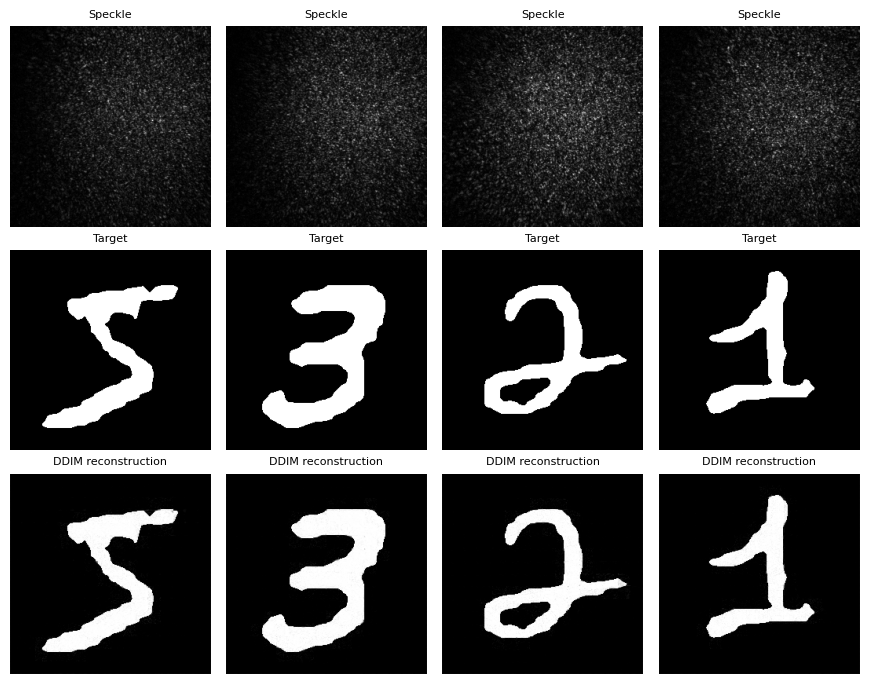

SANITY PASS | required: Dice_correct >= 0.80 and Dice_correct - Dice_swapped >= 0.30


In [ ]:
#@title 12. 4-pair overfit + Speckle-swap test (stops the notebook if the Speckle is ignored)
if not RUN_SANITY:
    print('RUN_SANITY=False: skipped')
else:
    step_ids = np.linspace(0, len(Xtr) - 1, 64, dtype=int).tolist()
    sanity_ids = []
    for i in step_ids:
        if all(not torch.equal(Mtr[i], Mtr[j]) for j in sanity_ids):
            sanity_ids.append(i)
        if len(sanity_ids) == 4: break
    assert len(sanity_ids) == 4, 'Could not find 4 training pairs with different targets'
    torch.manual_seed(SEED + 1)
    sanity_model = build_model()
    sanity_opt = torch.optim.AdamW(sanity_model.parameters(), lr=SANITY_LR, weight_decay=0.0)
    sanity_scaler = torch.amp.GradScaler('cuda')
    sx0, sspeckle = get_batch(Xtr, Mtr, sanity_ids)
    sx0, sspeckle = sx0.to(DEVICE), sspeckle.to(DEVICE)
    tick = time.time(); window = []
    for step in range(1, SANITY_STEPS + 1):
        sanity_model.train()
        t = torch.randint(0, TRAIN_TIMESTEPS, (4,), device=DEVICE)
        sanity_opt.zero_grad(set_to_none=True)
        with torch.autocast('cuda', dtype=torch.float16):
            loss = diffusion_train.training_losses(sanity_model, sx0, t, model_kwargs={'y': sspeckle})['loss'].float().mean()
        if not torch.isfinite(loss): raise RuntimeError(f'Non-finite sanity loss at step {step}')
        sanity_scaler.scale(loss).backward(); sanity_scaler.step(sanity_opt); sanity_scaler.update()
        window.append(loss.item())
        if step == 1 or step % 500 == 0:
            print(f'SANITY {step}/{SANITY_STEPS} | x0 MSE loss={np.mean(window):.5f} | steps/s={step / (time.time() - tick):.2f}', flush=True)
            window.clear()
    sanity_result, sanity_pred, sanity_truth = swap_test(sanity_model, Xtr, Mtr, sanity_ids, seed=SEED + 2)
    print('SANITY RESULT (4 training pairs, full DDIM from noise):')
    print(pd.Series(sanity_result).round(5).to_string())
    show_examples([sspeckle.cpu(), sanity_truth, sanity_pred], ['Speckle', 'Target', 'DDIM reconstruction'],
                  RESULTS_DIR / 'sanity_4_pairs.png')
    sanity_ok = sanity_result['Dice_correct'] >= 0.80 and (sanity_result['Dice_correct'] - sanity_result['Dice_swapped']) >= 0.30
    print('SANITY', 'PASS' if sanity_ok else 'FAIL',
          '| required: Dice_correct >= 0.80 and Dice_correct - Dice_swapped >= 0.30')
    del sanity_model, sanity_opt, sanity_scaler; torch.cuda.empty_cache()
    if SANITY_GATE and not sanity_ok:
        raise RuntimeError('Sanity test failed: the model does not reconstruct 4 training pairs from their Speckle. '
                           'Do not start the long run. Try a larger SANITY_STEPS first; if it still fails, the '
                           'conditioning must be changed.')

## Stage 2: long training — resumable

Three kinds of checkpoint are written. Every save goes to the local disk first, is copied to Drive under
a **new file name**, and the Drive copy is compared with the local file (size and SHA-256) before the
older file of that kind is removed. The step and epoch used in every report are read from inside the file.

- `latest_stepNNNNNN.pt` — everything needed to resume, every 5,000 updates.
- `best_dice_ema_stepNNNNNN.pt` — EMA with the best Dice of the full DDIM reconstruction (every 10,000 updates).
- `best_loss_ema_epochNNNN.pt` — EMA with the lowest validation loss (checked every 2 epochs).

In [ ]:
#@title 13. Training setup: model, EMA, optimizer, verified checkpoints, resume
torch.manual_seed(SEED)
model = build_model()
ema = copy.deepcopy(model).eval()
for p in ema.parameters(): p.requires_grad_(False)
param_groups = [dict(params=[p for p in model.dit.parameters() if p.requires_grad], lr=LR)]
encoder_params = [p for p in model.encoder.parameters() if p.requires_grad]
if encoder_params:
    param_groups.append(dict(params=encoder_params, lr=ENCODER_FINETUNE_LR))
optimizer = torch.optim.AdamW(param_groups, weight_decay=0.0)
scaler = torch.amp.GradScaler('cuda')

RECIPE = dict(git=repo_sha, split=SPLIT_FINGERPRINT, train_diffusers=list(TRAIN_DIFFUSERS), hidden=DIT_HIDDEN,
              depth=DIT_DEPTH, heads=DIT_HEADS, image_patch=IMAGE_PATCH, encoder_stage1=ENCODER_RECIPE_HASH,
              encoder_trainable=bool(ENCODER_TRAINABLE), encoder_lr=ENCODER_FINETUNE_LR,
              contrastive_weight=CONTRASTIVE_WEIGHT, temperature=TEMPERATURE, objects_per_batch=OBJECTS_PER_BATCH,
              views_per_object=VIEWS_PER_OBJECT, output_conv=bool(USE_OUTPUT_CONV),
              tokens=USE_ENCODER_TOKENS, global_vec=USE_CONTRASTIVE_GLOBAL,
              prediction='x0', variance='fixed', schedule='linear', timesteps=TRAIN_TIMESTEPS, lr=LR, ema=EMA_DECAY,
              batch=BATCH_SIZE, seed=SEED)
RECIPE_HASH = hashlib.sha256(json.dumps(RECIPE, sort_keys=True).encode()).hexdigest()
HISTORY_CSV = RESULTS_DIR / 'history.csv'                 # one row per full DDIM evaluation
EPOCH_CSV = RESULTS_DIR / 'epoch_history.csv'             # one row per epoch
LOCAL_DIR = Path('/content/checkpoints_local'); LOCAL_DIR.mkdir(exist_ok=True)
LOCAL_BEST_LOSS = LOCAL_DIR / 'best_loss_ema_pending.pt'
STEPS_PER_EPOCH = math.ceil(len(splits['TRAIN']) / OBJECTS_PER_BATCH)      # one epoch = every training object once
history = []; epoch_log = []; start_step = 1
best_dice = -1.0; best_step = 0
best_loss = float('inf'); best_loss_epoch = 0; best_loss_step = 0; best_loss_dirty = False
epoch_sum = 0.0; epoch_n = 0

@torch.no_grad()
def update_ema(step):
    # Meta's update rule; the decay ramps up at the start so early evaluations are not dominated by the initial weights.
    decay = min(EMA_DECAY, (1 + step) / (10 + step))
    m = OrderedDict(model.named_parameters()); e = OrderedDict(ema.named_parameters())
    for key in m: e[key].mul_(decay).add_(m[key].data, alpha=1 - decay)

def publish_file(local, name, family, remove_local=True):
    """Copy a finished local file to Drive under `name`, verify the copy, then keep only the two newest files of
    this family. A checkpoint on Drive is never replaced by renaming another file over it."""
    destination = RESULTS_DIR / name
    local_hash = file_sha256(local)
    for attempt in range(3):
        shutil.copyfile(local, destination)
        time.sleep(2 * attempt)
        if destination.stat().st_size == local.stat().st_size and file_sha256(destination) == local_hash:
            break
        print(f'Drive copy of {name} did not verify (attempt {attempt + 1}); copying again', flush=True)
    else:
        raise RuntimeError(f'The Drive copy of {name} differs from the local file after 3 attempts. Check the Drive storage quota.')
    if remove_local:
        local.unlink()
    for old in sorted(RESULTS_DIR.glob(family + '*.pt'))[:-2]:
        old.unlink()
    return destination

def save_latest(step):
    global best_loss_dirty
    if best_loss_dirty:      # the best-validation-loss EMA waits on the local disk between checkpoints
        publish_file(LOCAL_BEST_LOSS, 'best_loss_ema_epoch%04d.pt' % best_loss_epoch, 'best_loss_ema_epoch', remove_local=False)
        best_loss_dirty = False
    state = dict(step=step, model=model.state_dict(), ema=ema.state_dict(), optimizer=optimizer.state_dict(),
                 scaler=scaler.state_dict(), history=history, epoch_log=epoch_log,
                 best_dice=best_dice, best_step=best_step,
                 best_loss=best_loss, best_loss_epoch=best_loss_epoch, best_loss_step=best_loss_step,
                 epoch_sum=epoch_sum, epoch_n=epoch_n, recipe=RECIPE, recipe_hash=RECIPE_HASH)
    local = LOCAL_DIR / ('latest_step%06d.pt' % step)
    torch.save(state, local)
    publish_file(local, local.name, 'latest_step')
    pd.DataFrame(history).to_csv(HISTORY_CSV, index=False)
    pd.DataFrame(epoch_log).to_csv(EPOCH_CSV, index=False)

CHECKPOINT_PATTERN = {'best_loss': 'best_loss_ema_epoch*.pt', 'best_dice': 'best_dice_ema_step*.pt', 'last': 'latest_step*.pt'}
CHECKPOINT_LABEL = {'best_loss': 'Best loss', 'best_dice': 'Best Dice', 'last': 'Last'}

def load_checkpoint(kind):
    """Newest Drive file of this kind -> dict(ema, step, epoch, file). Step and epoch are read from inside the file."""
    files = sorted(RESULTS_DIR.glob(CHECKPOINT_PATTERN[kind]))
    assert files, f'No {kind} checkpoint in {RESULTS_DIR}: run the training cell first.'
    ckpt = torch.load(files[-1], map_location='cpu', weights_only=False)
    assert ckpt['recipe_hash'] == RECIPE_HASH, 'This checkpoint was made with a different configuration'
    step = int(ckpt['step']); epoch = int(ckpt.get('epoch', math.ceil(step / STEPS_PER_EPOCH)))
    expected = {'best_loss': best_loss_step, 'best_dice': best_step, 'last': 0}[kind]
    if expected and expected != step:
        print(f'WARNING: training recorded the {kind} checkpoint at step {expected}, but the newest file on Drive '
              f'({files[-1].name}) holds step {step}. Results below are labelled with the step in the file.')
    return dict(ema=ckpt['ema'], step=step, epoch=epoch, file=files[-1].name)

resumed = False
for candidate in sorted(RESULTS_DIR.glob('latest_step*.pt'), reverse=True):
    try:
        ckpt = torch.load(candidate, map_location='cpu', weights_only=False)
    except Exception as error:
        print('Skipping an unreadable checkpoint:', candidate.name, repr(error)[:120]); continue
    assert ckpt.get('recipe_hash') == RECIPE_HASH, ('The checkpoint in the results directory was made with a different '
                                                    'configuration or dataset. Change RESULTS_NAME in Cell 1.')
    model.load_state_dict(ckpt['model']); ema.load_state_dict(ckpt['ema'])
    optimizer.load_state_dict(ckpt['optimizer']); scaler.load_state_dict(ckpt['scaler'])
    history = ckpt['history']; epoch_log = ckpt['epoch_log']
    best_dice = ckpt['best_dice']; best_step = ckpt['best_step']
    best_loss = ckpt['best_loss']; best_loss_epoch = ckpt['best_loss_epoch']; best_loss_step = ckpt['best_loss_step']
    epoch_sum = ckpt['epoch_sum']; epoch_n = ckpt['epoch_n']
    start_step = int(ckpt['step']) + 1; resumed = True
    print('RESUMING from', candidate.name, '| next step', start_step,
          '| best Dice %.4f at step %d | best validation loss %.5f at epoch %d' % (best_dice, best_step, best_loss, best_loss_epoch))
    del ckpt
    break
if not resumed:
    print('NEW training run | results directory:', RESULTS_DIR)
try:
    free_gb = shutil.disk_usage(MYDRIVE).free / 2 ** 30
    print('Free space reported by Drive: %.1f GB' % free_gb, '' if free_gb > 4 else '| WARNING: less than 4 GB free')
except Exception as error:
    print('Drive free space is not available:', repr(error)[:80])

eval_ids = np.linspace(0, len(Xva) - 1, min(EVAL_SUBSET, len(Xva)), dtype=int).tolist()
_g = torch.Generator(device='cpu').manual_seed(SEED + 5)
val_t = torch.randint(0, TRAIN_TIMESTEPS, (len(Xva),), generator=_g)
val_noise = torch.randn(len(Xva), 1, 256, 256, generator=_g)

@torch.inference_mode()
def val_single_step_mse(net):
    """x0-prediction MSE on all validation measurements with fixed timesteps and noise (not a full reconstruction)."""
    net.eval(); total = 0.0
    for st in range(0, len(Xva), 32):
        ids = list(range(st, min(st + 32, len(Xva))))
        x0, speckle = get_batch(Xva, Mva, ids)
        x0, speckle = x0.to(DEVICE), speckle.to(DEVICE)
        t = val_t[ids].to(DEVICE); noise = val_noise[ids].to(DEVICE)
        with torch.autocast('cuda', dtype=torch.float16):
            xt = diffusion_train.q_sample(x0, t, noise=noise)
            pred = net(xt, t, speckle).float()
        total += float(F.mse_loss(pred, x0, reduction='sum'))
    return total / (len(Xva) * 256 * 256)
print('Updates per epoch:', STEPS_PER_EPOCH, '| total epochs: %.1f' % (TRAIN_STEPS / STEPS_PER_EPOCH))

NEW training run | results directory: /content/drive/MyDrive/Speckle_Project/DiT_Pixel_X0_ContrastiveEncoder_D4HeldOut_EndToEnd_OutputConv
Free space reported by Drive: 76.2 GB 
Updates per epoch: 111 | total epochs: 540.5


The training loop. Every batch holds 4 objects, each through 2 of the diffusers D1–D3. The loss is the
official x0-prediction MSE of the diffusion plus, when the encoder is trainable, `0.12 x` the contrastive
loss between the two views of each object. "Training x0 MSE" in the logs is the diffusion term only.

In [ ]:
#@title 14. Train with the official diffusion.training_losses (x0-prediction)
if not RUN_TRAINING:
    print('RUN_TRAINING=False: skipped')
else:
    tick = time.time(); window = []; reg_window = []; current_epoch = -1; perm = None; train_loss_recent = float('nan')
    use_regulariser = bool(ENCODER_TRAINABLE) and CONTRASTIVE_WEIGHT > 0
    reg_sum = 0.0; reg_n = 0
    for step in range(start_step, TRAIN_STEPS + 1):
        epoch = (step - 1) // STEPS_PER_EPOCH
        if epoch != current_epoch:      # seeded per epoch, so it is identical after a resume
            generator = torch.Generator(device='cpu').manual_seed(SEED + epoch)
            perm = torch.randperm(len(splits['TRAIN']), generator=generator)                      # order of the objects
            views = torch.stack([torch.randperm(3, generator=generator)[:VIEWS_PER_OBJECT] for _ in range(len(perm))])
            current_epoch = epoch
        pos = ((step - 1) % STEPS_PER_EPOCH) * OBJECTS_PER_BATCH
        objects = perm[pos:pos + OBJECTS_PER_BATCH]
        ids = (objects[:, None] * 3 + views[pos:pos + OBJECTS_PER_BATCH]).reshape(-1)    # measurement = object*3 + diffuser (D1-D3)
        x0, speckle = get_batch(Xtr, Mtr, ids)
        x0, speckle = x0.to(DEVICE), speckle.to(DEVICE)
        t = torch.randint(0, TRAIN_TIMESTEPS, (len(x0),), device=DEVICE)
        model.train(); optimizer.zero_grad(set_to_none=True)
        with torch.autocast('cuda', dtype=torch.float16):
            cond, z = model.condition(speckle)
            loss_diffusion = diffusion_train.training_losses(model.dit, x0, t, model_kwargs={'y': cond})['loss'].float().mean()
        loss_reg = multi_view_contrastive_loss(z, len(objects), VIEWS_PER_OBJECT) if use_regulariser else torch.zeros((), device=DEVICE)
        loss = loss_diffusion + CONTRASTIVE_WEIGHT * loss_reg
        if not torch.isfinite(loss):
            raise RuntimeError(f'Non-finite loss at step {step}')
        scaler.scale(loss).backward(); scaler.step(optimizer); scaler.update()
        update_ema(step)
        value = loss_diffusion.item(); window.append(value); epoch_sum += value; epoch_n += 1
        reg_value = loss_reg.item(); reg_window.append(reg_value); reg_sum += reg_value; reg_n += 1
        if step == start_step or step % PROGRESS_EVERY == 0:
            print(f'{step:,}/{TRAIN_STEPS:,} | epoch {epoch + 1} | train x0 MSE={np.mean(window):.5f} '
                  f'| contrastive={np.mean(reg_window):.4f} '
                  f'| steps/s={(step - start_step + 1) / max(time.time() - tick, 1e-6):.2f}', flush=True)
            train_loss_recent = float(np.mean(window)); window.clear(); reg_window.clear()
        if step % STEPS_PER_EPOCH == 0 or step == TRAIN_STEPS:      # end of an epoch
            entry = dict(Epoch=epoch + 1, Step=step, TRAIN_x0_MSE=epoch_sum / max(epoch_n, 1), VAL_x0_MSE=float('nan'),
                         TRAIN_contrastive=reg_sum / max(reg_n, 1))
            epoch_sum = 0.0; epoch_n = 0; reg_sum = 0.0; reg_n = 0
            if (epoch + 1) % VAL_LOSS_EVERY_EPOCHS == 0 or step == TRAIN_STEPS:
                entry['VAL_x0_MSE'] = val_single_step_mse(ema)
                if entry['VAL_x0_MSE'] < best_loss:
                    best_loss = entry['VAL_x0_MSE']; best_loss_epoch = epoch + 1; best_loss_step = step
                    torch.save(dict(ema=ema.state_dict(), step=step, epoch=epoch + 1, val_loss=best_loss,
                                    recipe_hash=RECIPE_HASH, recipe=RECIPE), LOCAL_BEST_LOSS)
                    best_loss_dirty = True
            epoch_log.append(entry)
        if step % EVAL_EVERY == 0 or step == TRAIN_STEPS:
            frame, _, _ = evaluate(ema, Xva, Mva, eval_ids, seed=SEED + 9)
            row = dict(Step=step, Epoch=epoch + 1, TRAIN_x0_MSE=train_loss_recent,
                       VAL_single_step_MSE=val_single_step_mse(ema),
                       VAL_DDIM_PSNR=float(frame.PSNR.mean()), VAL_DDIM_SSIM=float(frame.SSIM.mean()),
                       VAL_DDIM_Dice=float(frame.Dice.mean()), VAL_DDIM_PCC=float(frame.PCC.mean()))
            history.append(row)
            print('VALIDATION (EMA, DDIM from noise, %d known-diffuser measurements of unseen objects):' % len(eval_ids),
                  {k: (round(v, 5) if isinstance(v, float) else v) for k, v in row.items()}, flush=True)
            print('Best validation loss so far: %.5f at epoch %d' % (best_loss, best_loss_epoch), flush=True)
            if row['VAL_DDIM_Dice'] > best_dice:      # full reconstruction, not the single-step loss
                best_dice = row['VAL_DDIM_Dice']; best_step = step
                local = LOCAL_DIR / ('best_dice_ema_step%06d.pt' % step)
                torch.save(dict(ema=ema.state_dict(), step=step, epoch=epoch + 1, dice=best_dice,
                                recipe_hash=RECIPE_HASH, recipe=RECIPE), local)
                publish_file(local, local.name, 'best_dice_ema_step')
                print('NEW BEST-DICE EMA saved and verified on Drive at step', step, flush=True)
        if step % CHECKPOINT_EVERY == 0 or step == TRAIN_STEPS:
            save_latest(step)
    print('TRAINING COMPLETE:', TRAIN_STEPS, 'updates | best validation Dice %.4f at step %d | best validation loss %.5f at epoch %d' % (
        best_dice, best_step, best_loss, best_loss_epoch))
    print('Checkpoint files on Drive:')
    for path in sorted(RESULTS_DIR.glob('*.pt')):
        print('  %-36s %12d bytes' % (path.name, path.stat().st_size))

1/60,000 | epoch 1 | train x0 MSE=1.00000 | contrastive=0.1454 | steps/s=8.64
500/60,000 | epoch 5 | train x0 MSE=0.16785 | contrastive=0.1167 | steps/s=11.57
1,000/60,000 | epoch 10 | train x0 MSE=0.11070 | contrastive=0.0940 | steps/s=11.65
1,500/60,000 | epoch 14 | train x0 MSE=0.10113 | contrastive=0.0819 | steps/s=11.62
2,000/60,000 | epoch 19 | train x0 MSE=0.09701 | contrastive=0.0816 | steps/s=11.52
2,500/60,000 | epoch 23 | train x0 MSE=0.09137 | contrastive=0.0661 | steps/s=11.49
3,000/60,000 | epoch 28 | train x0 MSE=0.09164 | contrastive=0.0724 | steps/s=11.51
3,500/60,000 | epoch 32 | train x0 MSE=0.08910 | contrastive=0.0701 | steps/s=11.53
4,000/60,000 | epoch 37 | train x0 MSE=0.08351 | contrastive=0.0688 | steps/s=11.50
4,500/60,000 | epoch 41 | train x0 MSE=0.08165 | contrastive=0.0567 | steps/s=11.51
5,000/60,000 | epoch 46 | train x0 MSE=0.08085 | contrastive=0.0495 | steps/s=11.52
5,500/60,000 | epoch 50 | train x0 MSE=0.07680 | contrastive=0.0533 | steps/s=11.22
6

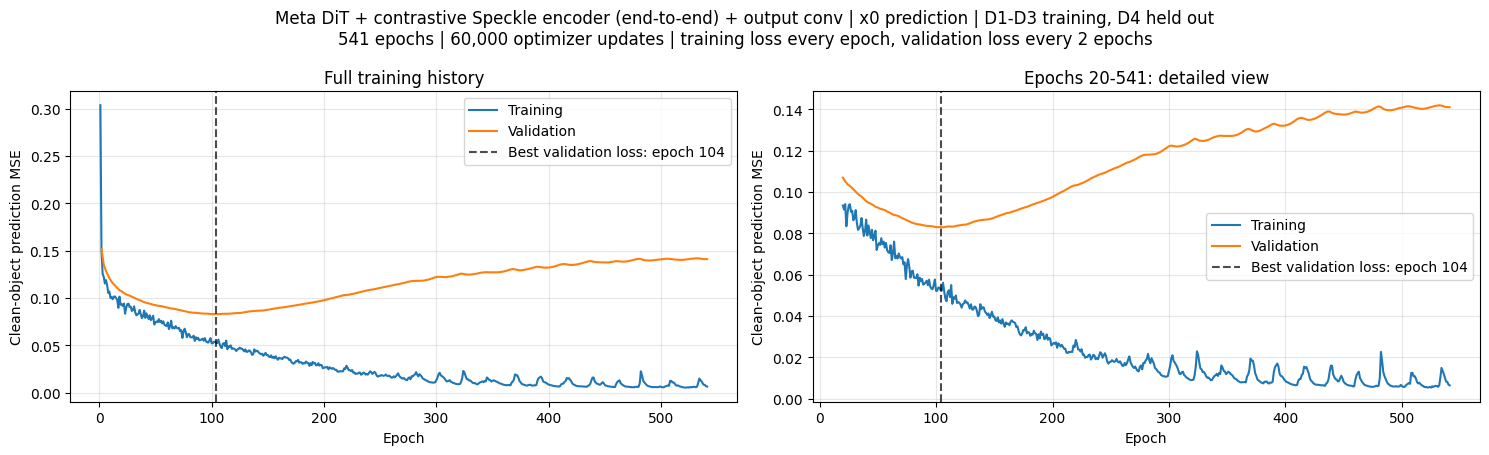

 Step  Epoch  TRAIN_x0_MSE  VAL_single_step_MSE  VAL_DDIM_PSNR  VAL_DDIM_SSIM  VAL_DDIM_Dice  VAL_DDIM_PCC
10000     91       0.05648              0.08388       11.62570        0.78972        0.62327       0.59035
20000    181       0.03295              0.09334       12.26553        0.79770        0.66259       0.63246
30000    271       0.01628              0.11565       12.36967        0.79951        0.66998       0.64032
40000    361       0.00901              0.12817       12.21540        0.80485        0.66242       0.63086
50000    451       0.00957              0.13745       12.18707        0.80856        0.66060       0.62836
60000    541       0.00810              0.14105       12.16912        0.81802        0.65569       0.62244


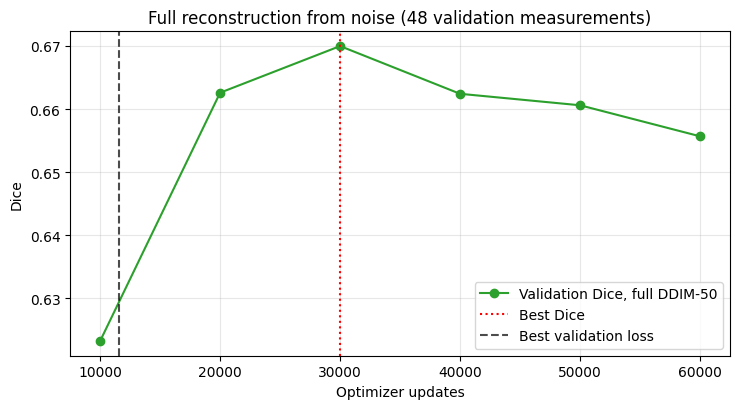

In [ ]:
#@title 15. Loss history per epoch and validation Dice of the full reconstruction
if not EPOCH_CSV.is_file() or not len(pd.read_csv(EPOCH_CSV)):
    print('No epoch history recorded yet.')
else:
    ep = pd.read_csv(EPOCH_CSV); val = ep.dropna(subset=['VAL_x0_MSE'])
    best_epoch = int(val.loc[val.VAL_x0_MSE.idxmin(), 'Epoch']); last_epoch = int(ep.Epoch.max())
    detail_from = 20 if last_epoch > 40 else 1
    fig, axs = plt.subplots(1, 2, figsize=(15, 4.6))
    for ax, first, title in ((axs[0], 1, 'Full training history'),
                             (axs[1], detail_from, 'Epochs %d-%d: detailed view' % (detail_from, last_epoch))):
        a = ep[ep.Epoch >= first]; b = val[val.Epoch >= first]
        ax.plot(a.Epoch, a.TRAIN_x0_MSE, label='Training')
        ax.plot(b.Epoch, b.VAL_x0_MSE, label='Validation')
        ax.axvline(best_epoch, color='k', ls='--', alpha=.7, label='Best validation loss: epoch %d' % best_epoch)
        ax.set(title=title, xlabel='Epoch', ylabel='Clean-object prediction MSE'); ax.grid(alpha=.3); ax.legend()
    fig.suptitle(MODEL_TITLE + ' | x0 prediction | D1-D3 training, D4 held out\n'
                 '%d epochs | %s optimizer updates | training loss every epoch, validation loss every %d epochs' % (
                     last_epoch, format(int(ep.Step.max()), ','), VAL_LOSS_EVERY_EPOCHS))
    plt.tight_layout(); fig.savefig(RESULTS_DIR / 'loss_history.png', dpi=130, bbox_inches='tight'); plt.show(); plt.close(fig)
    if HISTORY_CSV.is_file() and len(pd.read_csv(HISTORY_CSV)):
        table = pd.read_csv(HISTORY_CSV)
        print(table.round(5).to_string(index=False))
        fig, ax = plt.subplots(figsize=(7.5, 4.2))
        ax.plot(table.Step, table.VAL_DDIM_Dice, marker='o', color='tab:green', label='Validation Dice, full DDIM-%d' % SAMPLE_STEPS)
        ax.axvline(int(table.loc[table.VAL_DDIM_Dice.idxmax(), 'Step']), color='r', ls=':', label='Best Dice')
        ax.axvline(best_epoch * STEPS_PER_EPOCH, color='k', ls='--', alpha=.7, label='Best validation loss')
        ax.set(title='Full reconstruction from noise (%d validation measurements)' % len(eval_ids), xlabel='Optimizer updates', ylabel='Dice')
        ax.grid(alpha=.3); ax.legend()
        plt.tight_layout(); fig.savefig(RESULTS_DIR / 'dice_history.png', dpi=130, bbox_inches='tight'); plt.show(); plt.close(fig)

## Validation: unseen objects through the known diffusers D1–D3 (288 measurements, DDIM 50 steps)

Best loss checkpoint | step 11,544 (epoch 104) | 288 validation measurements, D1-D3, unseen objects | DDIM-50
PSNR   : 11.478192 +- 2.830676
SSIM   : 0.786486 +- 0.069011
Dice   : 0.617426 +- 0.134893
PCC    : 0.582330 +- 0.155436
MSE    : 0.083830 +- 0.042880
MSE_x0 : 0.335321 +- 0.171521

Best Dice checkpoint | step 30,000 (epoch 271) | 288 validation measurements, D1-D3, unseen objects | DDIM-50
PSNR   : 11.951882 +- 2.946877
SSIM   : 0.789537 +- 0.065038
Dice   : 0.653516 +- 0.138541
PCC    : 0.620522 +- 0.158634
MSE    : 0.076583 +- 0.042081
MSE_x0 : 0.306333 +- 0.168323

Last checkpoint | step 60,000 (epoch 541) | 288 validation measurements, D1-D3, unseen objects | DDIM-50
PSNR   : 11.931019 +- 2.976318
SSIM   : 0.810335 +- 0.064601
Dice   : 0.653891 +- 0.140833
PCC    : 0.619852 +- 0.161321
MSE    : 0.077031 +- 0.042009
MSE_x0 : 0.308124 +- 0.168034

Blank (all-black) image: PSNR 9.7961 | SSIM 0.8389 | Dice 0.0002
Stage 1 encoder alone (its direct decoder): PSNR 12.4522 | SSIM 

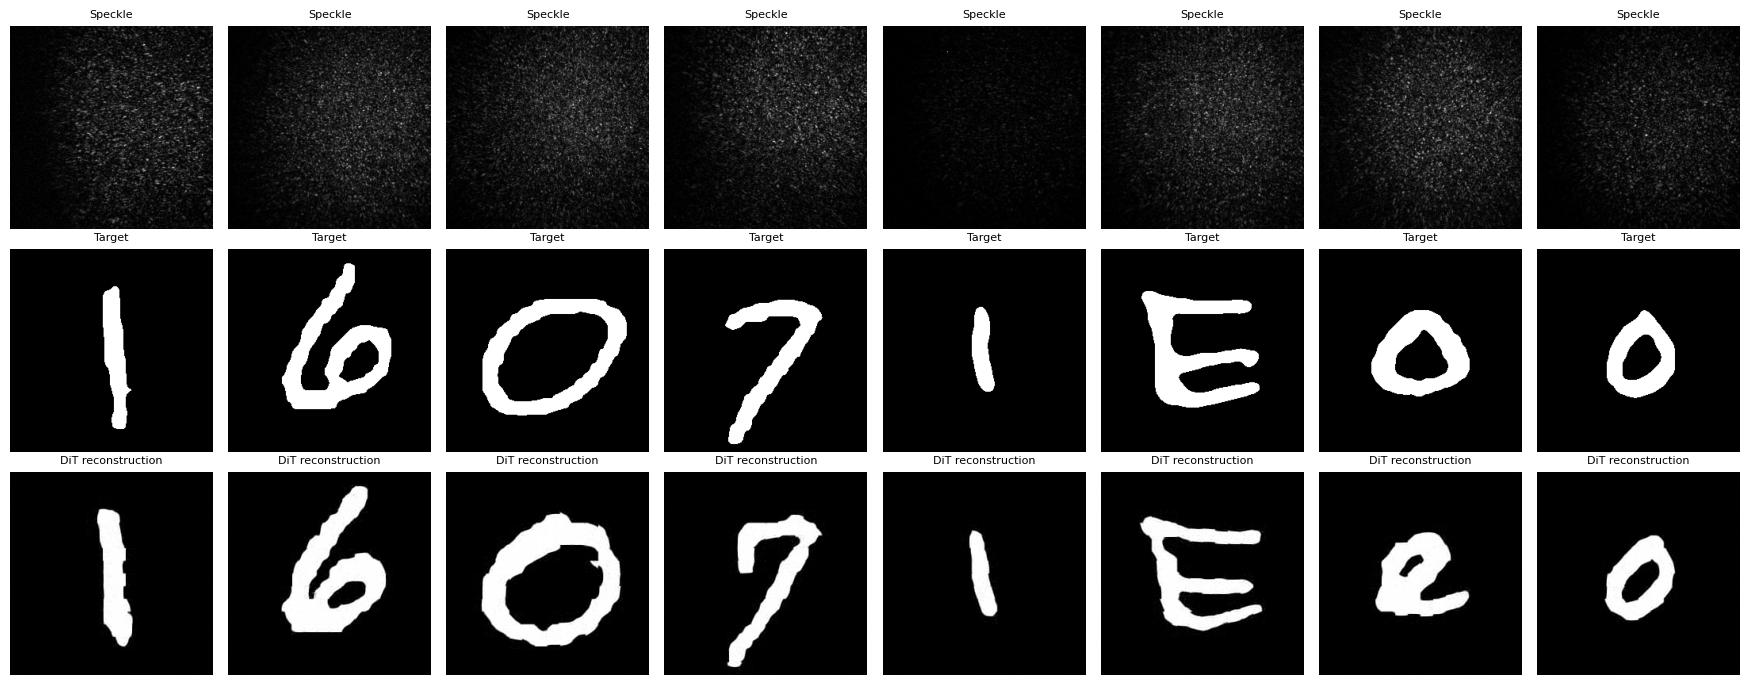

Saved to /content/drive/MyDrive/Speckle_Project/DiT_Pixel_X0_ContrastiveEncoder_D4HeldOut_EndToEnd_OutputConv


In [ ]:
#@title 16. Validation metrics for the three checkpoints, Speckle-swap test, examples
METRICS = ['PSNR', 'SSIM', 'Dice', 'PCC', 'MSE', 'MSE_x0']     # MSE on [0,1]; MSE_x0 = 4*MSE is the MSE on the x_0 scale [-1,1]
CHECKPOINT_KINDS = ('best_loss', 'best_dice', 'last')

def summary_rows(frame, kind, ckpt, extra=None):
    rows = []
    for metric in METRICS:
        values = frame[metric]
        rows.append(dict(**(extra or {}), checkpoint=kind, epoch=ckpt['epoch'], pairs=len(frame), metric=metric,
                         mean=float(values.mean()), std=float(values.std()),
                         undefined_count=int(values.isna().sum()), infinite_count=int(np.isinf(values).sum())))
    return rows

def print_block(title, frame):
    print(title)
    for metric in METRICS:
        print('%-7s: %.6f +- %.6f' % (metric, frame[metric].mean(), frame[metric].std()))
    print(flush=True)

eval_net = copy.deepcopy(ema).eval()
all_ids = list(range(len(Mva)))
val_rows = []; val_results = {}
for kind in CHECKPOINT_KINDS:
    ckpt = load_checkpoint(kind); eval_net.load_state_dict(ckpt['ema'], strict=True)
    frame, pred, truth = evaluate(eval_net, Xva, Mva, all_ids, seed=SEED + 11)     # same starting noise for every checkpoint
    frame['MSE_x0'] = 4 * frame['MSE']
    frame.insert(1, 'Name', VAL_NAMES); frame.insert(2, 'Family', VAL_FAMILY); frame.insert(3, 'Diffuser', VAL_DIFFUSER)
    frame.to_csv(RESULTS_DIR / f'validation_metrics_{kind}.csv', index=False)
    val_rows += summary_rows(frame, kind, ckpt); val_results[kind] = (ckpt, frame, pred)
    print_block('%s checkpoint | step %s (epoch %d) | %d validation measurements, D1-D3, unseen objects | DDIM-%d' % (
        CHECKPOINT_LABEL[kind], format(ckpt['step'], ','), ckpt['epoch'], len(frame), SAMPLE_STEPS), frame)
pd.DataFrame(val_rows).to_csv(RESULTS_DIR / 'summary_metrics.csv', index=False)

blank = pd.DataFrame([im_metrics(-np.ones((256, 256), np.float32), truth[i].numpy()) for i in all_ids])
print('Blank (all-black) image: PSNR %.4f | SSIM %.4f | Dice %.4f' % (blank.PSNR.mean(), blank.SSIM.mean(), blank.Dice.mean()))
direct = pd.DataFrame([im_metrics(coarse_val[i].numpy(), truth[i].numpy()) for i in all_ids])
print('Stage 1 encoder alone (its direct decoder): PSNR %.4f | SSIM %.4f | Dice %.4f' % (direct.PSNR.mean(), direct.SSIM.mean(), direct.Dice.mean()))
ckpt, frame, pred = val_results['best_dice']
print('Best-Dice checkpoint by family:'); print(frame.groupby('Family')[['Dice', 'PSNR', 'SSIM', 'PCC']].agg(['mean', 'std', 'count']).round(4).to_string())
print('Best-Dice checkpoint by diffuser:'); print(frame.groupby('Diffuser')[['Dice', 'PSNR', 'SSIM', 'PCC']].mean().round(4).to_string())
eval_net.load_state_dict(ckpt['ema'], strict=True)
swap_result, _, _ = swap_test(eval_net, Xva, Mva, eval_ids, seed=SEED + 12)
print('SPECKLE-SWAP TEST on %d validation measurements (does the reconstruction depend on the measurement?):' % len(eval_ids))
print(pd.Series(swap_result).round(5).to_string())
pd.Series(swap_result).to_csv(RESULTS_DIR / 'validation_swap_test.csv')
show_ids = np.linspace(0, len(Mva) - 1, 8, dtype=int).tolist()
show_examples([Xva[show_ids][:, None], truth[show_ids], pred[show_ids]],
              ['Speckle', 'Target', 'DiT reconstruction'], RESULTS_DIR / 'validation_examples.png')
print('Saved to', RESULTS_DIR)

Targets identical through D1 and D4: True
D1_known | Best loss checkpoint | step 11,544 (epoch 104) | 60 sealed objects | DDIM-50
PSNR   : 11.915430 +- 2.418893
SSIM   : 0.805540 +- 0.065694
Dice   : 0.644803 +- 0.120051
PCC    : 0.616089 +- 0.137029
MSE    : 0.074103 +- 0.038179
MSE_x0 : 0.296414 +- 0.152718

D4_unseen | Best loss checkpoint | step 11,544 (epoch 104) | 60 sealed objects | DDIM-50
PSNR   : 10.444556 +- 1.712900
SSIM   : 0.767430 +- 0.058948
Dice   : 0.568709 +- 0.117367
PCC    : 0.529817 +- 0.131271
MSE    : 0.096829 +- 0.034497
MSE_x0 : 0.387315 +- 0.137986

D1_known | Best Dice checkpoint | step 30,000 (epoch 271) | 60 sealed objects | DDIM-50
PSNR   : 12.684607 +- 2.632085
SSIM   : 0.810560 +- 0.058465
Dice   : 0.703576 +- 0.118591
PCC    : 0.678902 +- 0.136118
MSE    : 0.063858 +- 0.037126
MSE_x0 : 0.255434 +- 0.148503

D4_unseen | Best Dice checkpoint | step 30,000 (epoch 271) | 60 sealed objects | DDIM-50
PSNR   : 10.739175 +- 1.938038
SSIM   : 0.771870 +- 0.0563

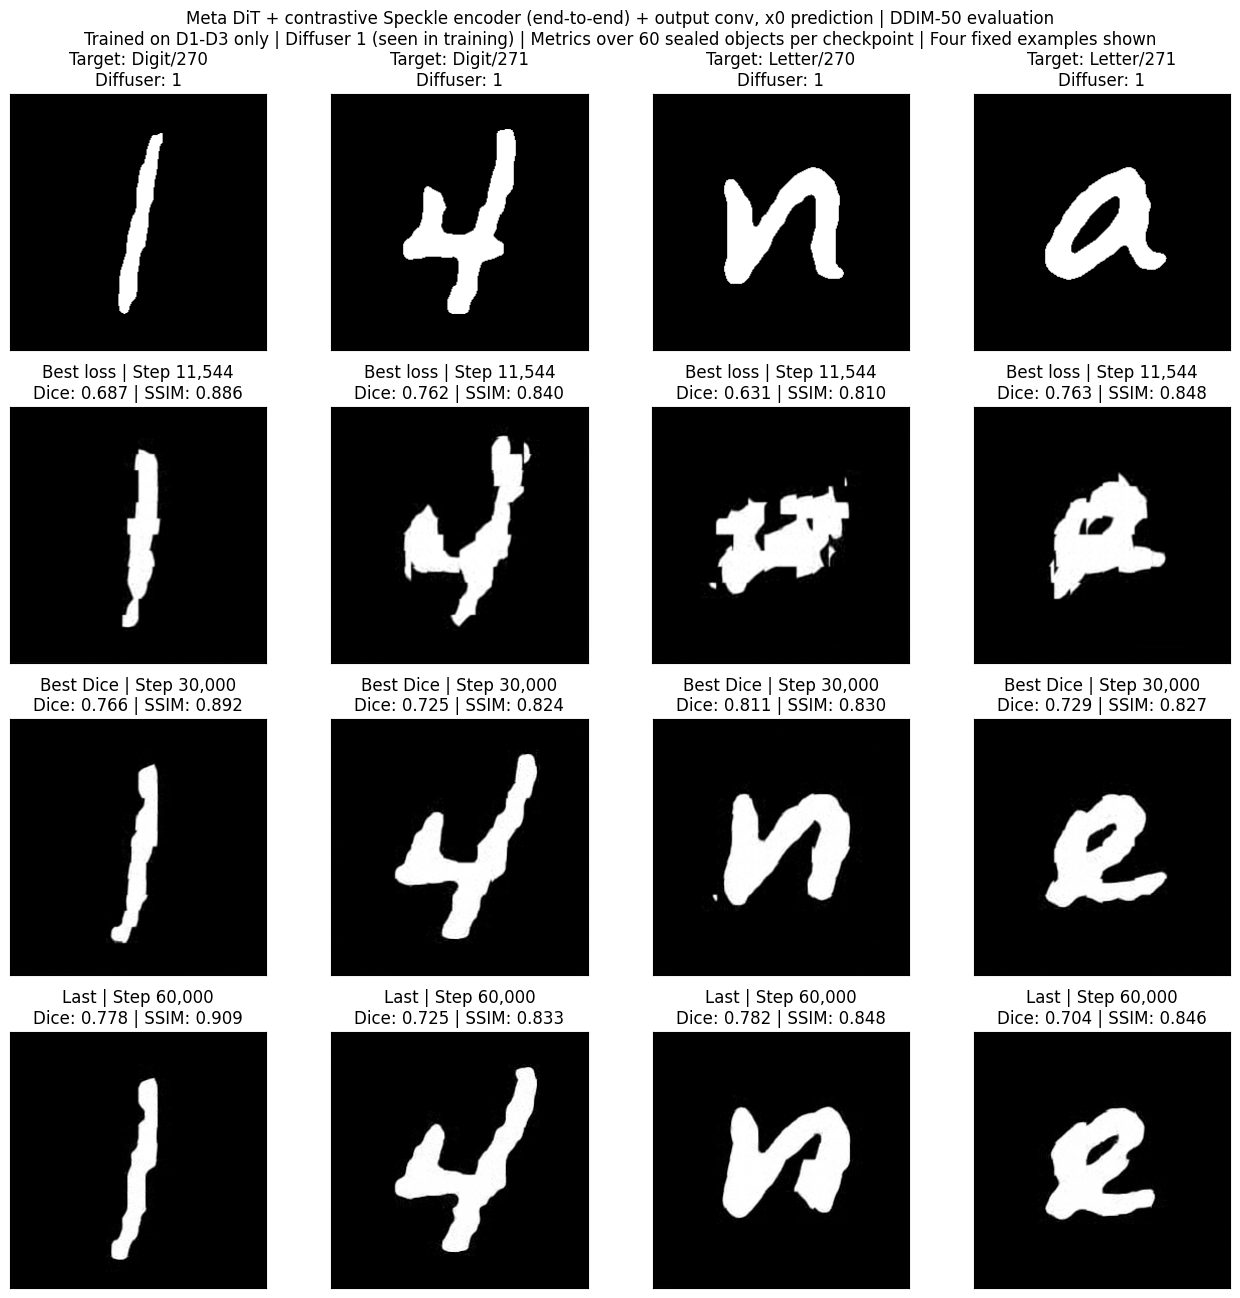

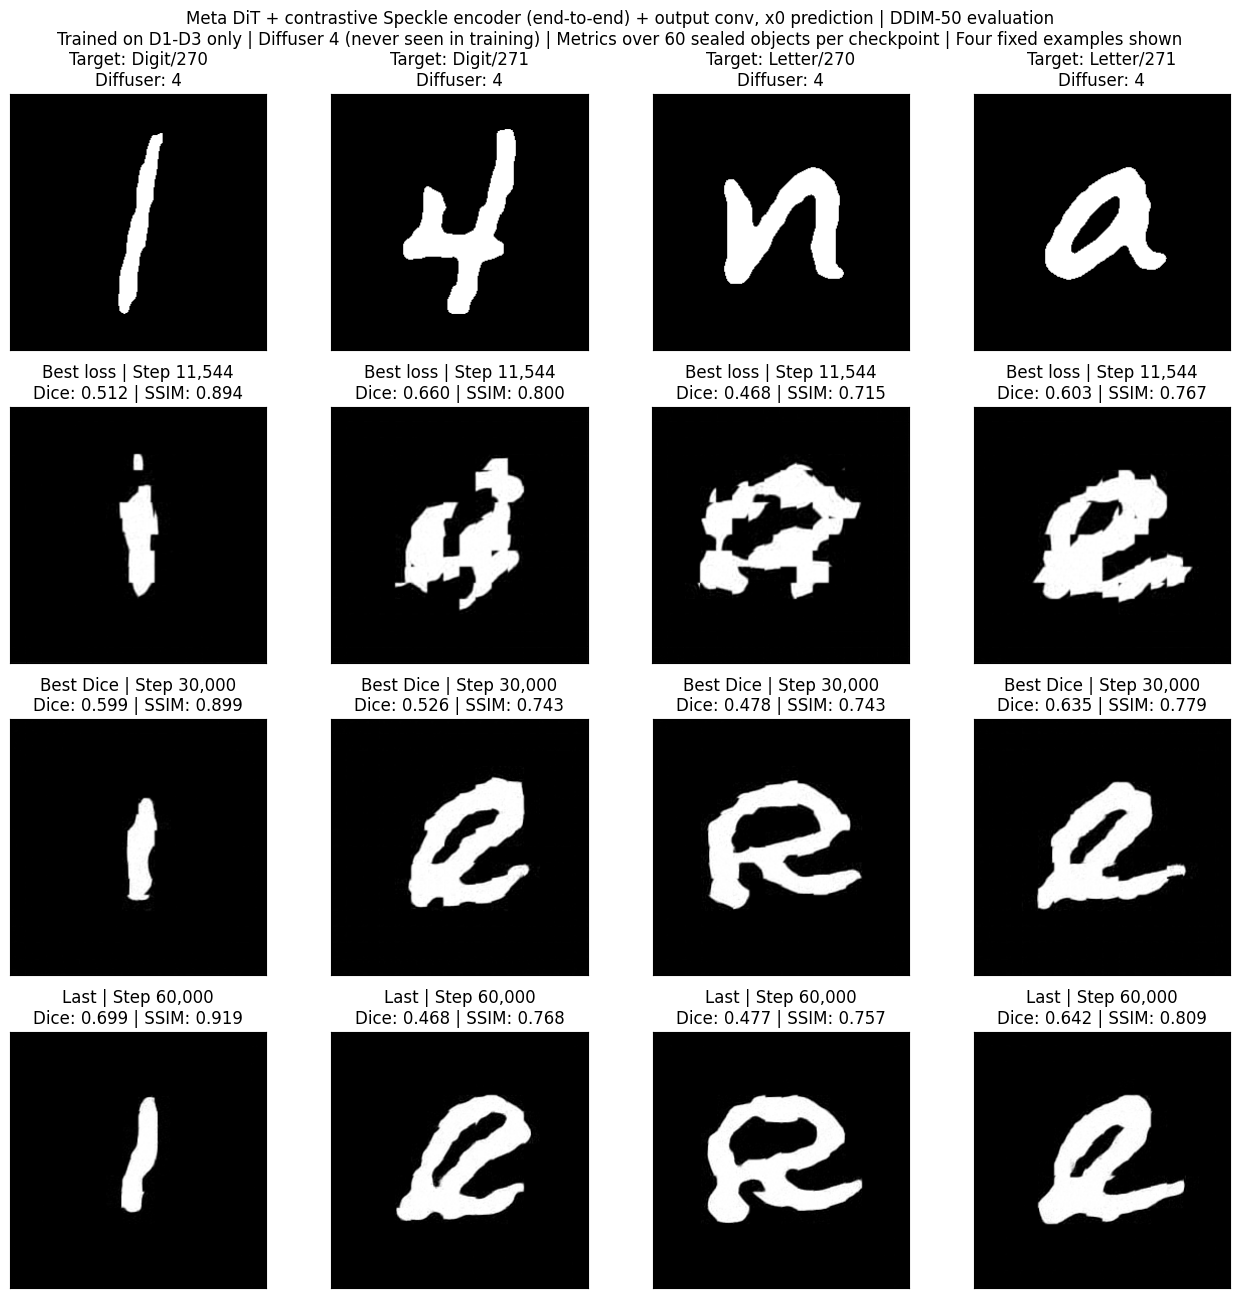

Saved to /content/drive/MyDrive/Speckle_Project/DiT_Pixel_X0_ContrastiveEncoder_D4HeldOut_EndToEnd_OutputConv


In [ ]:
#@title 17. The unseen diffuser: 60 sealed evaluation objects through D1 (known) and D4 (unseen): metrics, swap test, four fixed examples
if not RUN_D4_EVAL:
    print('SKIPPED: RUN_D4_EVAL=False. No D4 image was opened in this notebook.')
else:
    eval_keys = list(splits['EVAL'])
    eval_names = ['%s/%s' % (FAMILY_LABEL.get(k[0], k[0]), k[1]) for k in eval_keys]
    eval_family = [FAMILY_LABEL.get(k[0], k[0]) for k in eval_keys]
    def load_eval(d):
        with ThreadPoolExecutor(max_workers=16) as pool:
            loaded = list(pool.map(load_pair, [(complete[k][d]['speckle_path'], complete[k][d]['gt_path']) for k in eval_keys]))
        return torch.from_numpy(np.stack([a for a, _ in loaded])), torch.from_numpy(np.stack([b for _, b in loaded]))
    eval_sets = {'D1_known': load_eval('1'), 'D4_unseen': load_eval(HELDOUT_DIFFUSER)}
    print('Targets identical through D1 and D4:', bool(torch.equal(eval_sets['D1_known'][1], eval_sets['D4_unseen'][1])))
    fixed_keys = [('big', '270'), ('big', '271'), ('standard', '270'), ('standard', '271')]     # the four examples of the shared reports
    fixed = [eval_keys.index(k) for k in fixed_keys if k in eval_keys]
    if len(fixed) != 4:
        fixed = np.linspace(0, len(eval_keys) - 1, 4, dtype=int).tolist()
    ids = list(range(len(eval_keys)))
    eval_net = copy.deepcopy(ema).eval()
    d4_rows = []; shown = {}; frames = {}
    for kind in CHECKPOINT_KINDS:
        ckpt = load_checkpoint(kind); eval_net.load_state_dict(ckpt['ema'], strict=True)
        for label, (Xe, Me) in eval_sets.items():
            frame, pred, truth = evaluate(eval_net, Xe, Me, ids, seed=SEED + 21)     # same starting noise everywhere
            frame['MSE_x0'] = 4 * frame['MSE']
            frame.insert(1, 'Name', eval_names); frame.insert(2, 'Family', eval_family)
            frame.to_csv(RESULTS_DIR / f'eval60_{label}_{kind}_metrics.csv', index=False)
            d4_rows += summary_rows(frame, kind, ckpt, extra=dict(evaluation_set=label))
            shown[(kind, label)] = (ckpt, frame.iloc[fixed], pred[fixed]); frames[(kind, label)] = frame
            print_block('%s | %s checkpoint | step %s (epoch %d) | %d sealed objects | DDIM-%d' % (
                label, CHECKPOINT_LABEL[kind], format(ckpt['step'], ','), ckpt['epoch'], len(frame), SAMPLE_STEPS), frame)
    pd.DataFrame(d4_rows).to_csv(RESULTS_DIR / 'summary_metrics_D1_vs_D4.csv', index=False)
    truth_all = (2.0 * eval_sets['D1_known'][1].float() - 1.0)[:, None]
    blank = pd.DataFrame([im_metrics(-np.ones((256, 256), np.float32), truth_all[i].numpy()) for i in ids])
    print('Blank (all-black) image: PSNR %.4f | SSIM %.4f | Dice %.4f' % (blank.PSNR.mean(), blank.SSIM.mean(), blank.Dice.mean()))
    for label, (Xe, Me) in eval_sets.items():
        direct = pd.DataFrame([im_metrics(o.numpy(), truth_all[i].numpy()) for i, o in enumerate(encoder_outputs(global_model, Xe)[0])])
        print('Stage 1 encoder alone (its direct decoder), %s: PSNR %.4f | SSIM %.4f | Dice %.4f' % (
            label, direct.PSNR.mean(), direct.SSIM.mean(), direct.Dice.mean()))
    global_model.cpu()
    for label in eval_sets:
        print('Best-Dice checkpoint,', label, 'by family:')
        print(frames[('best_dice', label)].groupby('Family')[['Dice', 'PSNR', 'SSIM', 'PCC']].agg(['mean', 'std', 'count']).round(4).to_string())
    eval_net.load_state_dict(load_checkpoint('best_dice')['ema'], strict=True)
    swap_rows = {}
    for label, (Xe, Me) in eval_sets.items():
        swap_rows[label], _, _ = swap_test(eval_net, Xe, Me, ids, seed=SEED + 22)
    print('SPECKLE-SWAP TEST on the 60 sealed objects, best-Dice checkpoint:')
    print(pd.DataFrame(swap_rows).round(5).to_string())
    pd.DataFrame(swap_rows).to_csv(RESULTS_DIR / 'eval60_swap_test.csv')
    for label, (Xe, Me) in eval_sets.items():
        fig, axs = plt.subplots(1 + len(CHECKPOINT_KINDS), 4, figsize=(13, 3.3 * (1 + len(CHECKPOINT_KINDS))), squeeze=False)
        for j, i in enumerate(fixed):
            axs[0, j].imshow(Me[i].numpy(), cmap='gray', vmin=0, vmax=1)
            axs[0, j].set_title('Target: %s\nDiffuser: %s' % (eval_names[i], label[1]))
        for r, kind in enumerate(CHECKPOINT_KINDS, start=1):
            ckpt, part, pred = shown[(kind, label)]
            for j in range(4):
                axs[r, j].imshow((pred[j, 0].numpy() + 1) / 2, cmap='gray', vmin=0, vmax=1)
                axs[r, j].set_title('%s | Step %s\nDice: %.3f | SSIM: %.3f' % (
                    CHECKPOINT_LABEL[kind], format(ckpt['step'], ','), part.Dice.iloc[j], part.SSIM.iloc[j]))
        for a in axs.ravel(): a.set_xticks([]); a.set_yticks([])
        fig.suptitle(MODEL_TITLE + ', x0 prediction | DDIM-%d evaluation\n'
                     'Trained on D1-D3 only | %s | Metrics over %d sealed objects per checkpoint | Four fixed examples shown' % (
                         SAMPLE_STEPS, 'Diffuser 1 (seen in training)' if label == 'D1_known' else 'Diffuser 4 (never seen in training)', len(ids)))
        plt.tight_layout(); fig.savefig(RESULTS_DIR / f'four_fixed_examples_{label}.png', dpi=130, bbox_inches='tight')
        plt.show(); plt.close(fig)
    print('Saved to', RESULTS_DIR)

## Is the representation independent of the diffuser?

For every one of the 60 sealed objects the contrastive vector is computed through each diffuser. An object
seen through one diffuser is then searched among all objects of its family seen through another diffuser.
"Top-1" is how often the same object is the closest one. Chance level is 1/30. The comparison is between
pairs of diffusers that were both in training (D1–D3) and pairs that involve the unseen D4.

In [ ]:
#@title 18. Same-object retrieval across diffusers, including the unseen D4 (Stage 1 encoder and the encoder after Stage 2)
if not RUN_D4_EVAL:
    print('SKIPPED: RUN_D4_EVAL=False.')
else:
    rep_keys = list(splits['EVAL'])
    rep_family = [k[0] for k in rep_keys]
    def load_speckles(d):
        with ThreadPoolExecutor(max_workers=16) as pool:
            loaded = list(pool.map(load_pair, [(complete[k][d]['speckle_path'], complete[k][d]['gt_path']) for k in rep_keys]))
        return torch.from_numpy(np.stack([a for a, _ in loaded]))
    rep_views = {d: load_speckles(d) for d in ('1', '2', '3', '4')}

    def retrieval(za, zb):
        correct = total = 0; reciprocal = 0.0
        for kind in sorted(set(rep_family)):
            where = [i for i, f in enumerate(rep_family) if f == kind]
            a = F.normalize(za[where].float(), dim=-1).numpy(); b = F.normalize(zb[where].float(), dim=-1).numpy()
            order = np.argsort(-(a @ b.T), axis=1, kind='stable')
            rank = np.argmax(order == np.arange(len(where))[:, None], axis=1) + 1
            correct += int((rank == 1).sum()); reciprocal += float((1 / rank).sum()); total += len(rank)
        return correct / max(total, 1), reciprocal / max(total, 1)

    encoders = {'Stage 1 encoder (step %d)' % encoder_best_step: global_model}
    if ENCODER_TRAINABLE:
        rep_net = copy.deepcopy(ema).eval()
        for kind in ('best_dice', 'last'):
            ckpt = load_checkpoint(kind); rep_net.load_state_dict(ckpt['ema'], strict=True)
            encoders['After Stage 2, %s (step %s)' % (CHECKPOINT_LABEL[kind], format(ckpt['step'], ','))] = copy.deepcopy(rep_net.encoder)
    rep_rows = []
    for name, net in encoders.items():
        z = {d: encoder_outputs(net, X)[1] for d, X in rep_views.items()}
        net.cpu()
        for group, pairs in (('known <-> known (D1-D3)', [(a, b) for a in '123' for b in '123' if a != b]),
                             ('known <-> unseen D4', [(a, '4') for a in '123'] + [('4', b) for b in '123'])):
            scores = [retrieval(z[a], z[b]) for a, b in pairs]
            rep_rows.append(dict(Encoder=name, Pairs=group, Top1=float(np.mean([s[0] for s in scores])),
                                 MRR=float(np.mean([s[1] for s in scores])), Objects=len(rep_keys)))
    rep_table = pd.DataFrame(rep_rows)
    print('Same-object retrieval on the %d sealed objects (chance Top-1 = %.3f):' % (len(rep_keys), 2 / len(rep_keys)))
    print(rep_table.round(4).to_string(index=False))
    rep_table.to_csv(RESULTS_DIR / 'representation_retrieval.csv', index=False)
    torch.cuda.empty_cache()

Same-object retrieval on the 60 sealed objects (chance Top-1 = 0.033):
                               Encoder                   Pairs   Top1    MRR  Objects
           Stage 1 encoder (step 1500) known <-> known (D1-D3) 0.7167 0.8270       60
           Stage 1 encoder (step 1500)     known <-> unseen D4 0.5250 0.6598       60
After Stage 2, Best Dice (step 30,000) known <-> known (D1-D3) 0.8278 0.9028       60
After Stage 2, Best Dice (step 30,000)     known <-> unseen D4 0.6056 0.7362       60
     After Stage 2, Last (step 60,000) known <-> known (D1-D3) 0.8056 0.8877       60
     After Stage 2, Last (step 60,000)     known <-> unseen D4 0.5806 0.7083       60


## Reading the results

- **Three checkpoints.** "Best loss" is the EMA with the lowest validation loss (a single denoising step).
  "Best Dice" is the EMA with the best full DDIM reconstruction on a fixed validation subset. "Last" is
  the EMA after the final update. All three are chosen or fixed without D4 and without the 60 evaluation objects.
- **Speckle-swap test:** with the same noise, the correct Speckle must give a clearly better reconstruction
  than the Speckle of another object. This is the direct check that the measurement is used.
- **D1 against D4** on the same 60 objects is the measure of generalisation to a new diffuser.
- **"Blank image"** is an all-black output. A model that is not clearly above it has not learned to reconstruct.
- **"Stage 1 encoder alone"** is the reconstruction of the encoder's own direct decoder from the same
  Speckle. It shows what the diffusion model adds on top of the encoder.
- **Retrieval across diffusers** (Cell 18) is the direct test of a diffuser-independent representation.
- This run is directly comparable with the Direction-1 notebook (same split, same evaluation objects,
  same sampler). It is **not** directly comparable with runs trained on all four diffusers.

In [ ]:
#@title 19. Copy the report files to the shared report folder
REPORT_DIR.mkdir(parents=True, exist_ok=True)
report_files = ['summary_metrics.csv', 'summary_metrics_D1_vs_D4.csv', 'loss_history.png', 'dice_history.png',
                'four_fixed_examples_D1_known.png', 'four_fixed_examples_D4_unseen.png', 'validation_examples.png',
                'sanity_4_pairs.png', 'epoch_history.csv', 'history.csv', 'encoder_stage1.png', 'encoder_stage1_log.csv',
                'representation_retrieval.csv']
for name in report_files:
    source_file = RESULTS_DIR / name
    if source_file.is_file():
        shutil.copyfile(source_file, REPORT_DIR / (REPORT_PREFIX + name))
        print('copied', REPORT_PREFIX + name)
    else:
        print('not found (cell not run yet?):', name)